# Problem I: Küresel Elektrikli Araç Pazarlarının Kümelenmesi

### 1. Araştırma Sorusu
Hangi ülkeler elektrikli araç benimseme ve şarj altyapısı özellikleri bakımından birbirine benzerlik göstermektedir?

### 2. Problem Tanımı
Elektrikli araç (EV) pazarları; elektrikli araçların benimsenmesi, pazar büyüklüğü ve şarj altyapısının gelişmişliği bakımından ülkeler arasında önemli farklılıklar göstermektedir.

Bazı ülkelerde elektrikli araçların toplam satışlar içerisindeki payı yüksekken bazı ülkeler büyük elektrikli araç filolarına sahip olmalarına rağmen görece sınırlı bir halka açık şarj altyapısına sahiptir.

Bu çalışmanın amacı, gözetimsiz makine öğrenmesi tekniklerini kullanarak benzer elektrikli araç pazarı özelliklerine sahip ülke gruplarını belirlemektir.

Birden fazla göstergeyi eş zamanlı analiz ederek önceden tanımlanmış ülke kategorilerine bağlı kalmadan farklı elektrikli araç pazarı profillerini keşfetmeyi hedefliyoruz.

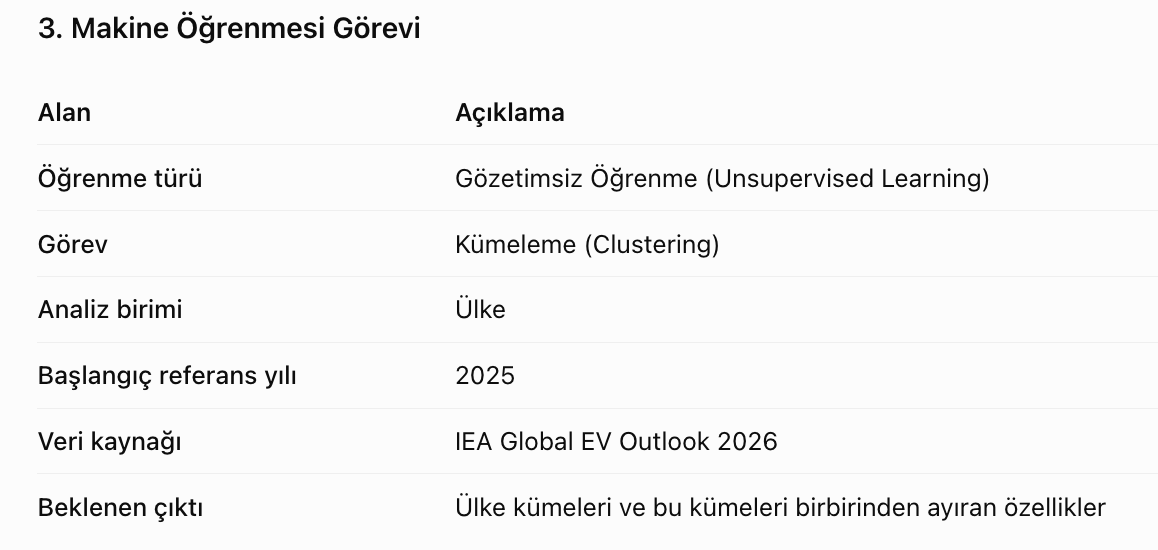

Not: Kullanılacak nihai özellikler (features) ve analize dahil edilebilecek ülke sayısı, veri uygunluğu analizi tamamlandıktan sonra belirlenecektir.

## 4. Aday Özellikler (Candidate Features)

Bu kümeleme çalışmasının amacı, ülkeleri elektrikli araçların benimsenmesi ve şarj altyapısı özelliklerine göre gruplandırmaktır.

Bu doğrultuda başlangıçta aşağıdaki beş özellik değerlendirilecektir:

| Özellik (Feature) | Açıklama |
|---|---|
| **EV Sales Share (%)** | Yeni otomobil satışları içerisinde elektrikli araçların yüzdesi. |
| **EV Stock** | Kullanımdaki toplam elektrikli otomobil sayısı. |
| **EV Stock Share (%)** | Mevcut otomobil filosu içerisinde elektrikli araçların yüzdesi. |
| **Public Charging Points** | Halka açık elektrikli araç şarj noktalarının toplam sayısı. |
| **EVs per Charging Point** | Halka açık şarj noktası başına düşen elektrikli otomobil sayısı. |

### 4.1. Özellik Seçiminde Dikkat Edilecek Noktalar

- **Coğrafi kapsam:** Yalnızca ülke düzeyindeki gözlemler kullanılacaktır. Dünya ve bölgesel toplamlar analize dahil edilmeyecektir.
- **Referans yılı:** Başlangıç olarak 2025 yılı kullanılacaktır.
- **Eksik veriler:** Eksik değerler doğrudan sıfır ile doldurulmayacaktır.
- **Ölçek farklılıkları:** Özelliklerin farklı büyüklüklerde olması nedeniyle gerekli dönüşüm ve standardizasyon yöntemleri değerlendirilecektir.
- **Özellikler arasındaki ilişkiler:** Birbiriyle yüksek düzeyde ilişkili veya matematiksel olarak bağımlı özellikler incelenecektir. Gereksiz tekrar oluşturan değişkenler modelden çıkarılabilecektir.
- **Veri uygunluğu:** Nihai özellikler, veri setindeki gözlem sayısı, eksik değerler, veri kalitesi ve analitik anlamlılık dikkate alınarak belirlenecektir.

### 4.2. Beklenen Sonuç

Seçilen özellikler kullanılarak her ülkenin çok boyutlu bir EV pazar profili oluşturulması hedeflenmektedir.

Kümeleme algoritmaları, bu profiller arasındaki benzerlikleri değerlendirerek ülkeleri gruplara ayıracaktır.

**Not:** Bu aşamada özellikler kesinleştirilmemiştir. Nihai özellik seçimi, veri uygunluğu analizinin ardından yapılacaktır.

In [1]:
# Adım 3.1 — Veri setini yükleme

import pandas as pd
from pathlib import Path

# Proje ana klasörünü bul
csv_path = None

for folder in [Path.cwd(), *Path.cwd().parents]:
    candidate = folder / "data" / "analysisdataset" / "global_ev_cleaned.csv"

    if candidate.exists():
        csv_path = candidate
        break

if csv_path is None:
    raise FileNotFoundError("global_ev_cleaned.csv bulunamadı.")

# Veri setini yükle
df = pd.read_csv(csv_path)

print("Dataset path:", csv_path)
print("Dataset shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

display(df.head())


Dataset path: /Users/rabia/global-electric-vehicle-dashboard/global-electric-vehicle-dashboard/data/analysisdataset/global_ev_cleaned.csv
Dataset shape: (48277, 9)

Columns:
['region_country', 'category', 'parameter', 'mode', 'powertrain', 'year', 'unit', 'value', 'Aggregate group']


,region_country,category,parameter,mode,powertrain,year,unit,value,Aggregate group
0,Chile,Historical,EV charging points,EVSE,Publicly available fast,2011,charging points,1.0,Other
1,Norway,Historical,EV charging points,EVSE,Publicly available fast,2011,charging points,18.0,Other
2,Portugal,Historical,EV charging points,EVSE,Publicly available fast,2011,charging points,6.0,Other
3,Canada,Historical,EV charging points,EVSE,Publicly available fast,2012,charging points,2.0,Other
4,Chile,Historical,EV charging points,EVSE,Publicly available fast,2012,charging points,4.0,Other


In [ ]:
# Önce 2025 yılına ait gerçek ülke kayıtlarını filtreleyelim

# Bir sonraki adımımız: 2025 yılına ait gerçek ülkeleri filtreleyip EV Sales Share, EV Stock, EV Stock Share ve şarj noktası göstergelerinin 
# kaç ülkede bulunduğunu incelemek olacak. Beşinci özelliği (EVs per Charging Point) ise bu verilerden hesaplayacağız.


# Yalnızca 2025 yılına ait tarihsel ülke verilerini seç
df_2025 = df[
    (df["category"] == "Historical") &
    (df["year"] == 2025) &
    (df["Aggregate group"].isin(["Other", "Projection_country"]))
].copy()

print("2025 yılı toplam kayıt sayısı:", len(df_2025))
print("2025 yılı benzersiz ülke sayısı:", df_2025["region_country"].nunique())

# Hangi göstergeler mevcut?
parameter_summary = (
    df_2025.groupby("parameter")["region_country"]
    .nunique()
    .sort_values(ascending=False)
    .reset_index(name="country_count")
)

display(parameter_summary)


2025 yılı toplam kayıt sayısı: 2960
2025 yılı benzersiz ülke sayısı: 60


,parameter,country_count
0,EV sales,60
1,EV sales share,60
2,EV stock,46
3,EV stock share,46
4,Average capacity per EV,43
5,EV charging points,43
6,Electric LDVs per charging point,43
7,Average capacity per EVSE,43
8,price_p0_2025USD,10
9,price_p75_2025USD,10


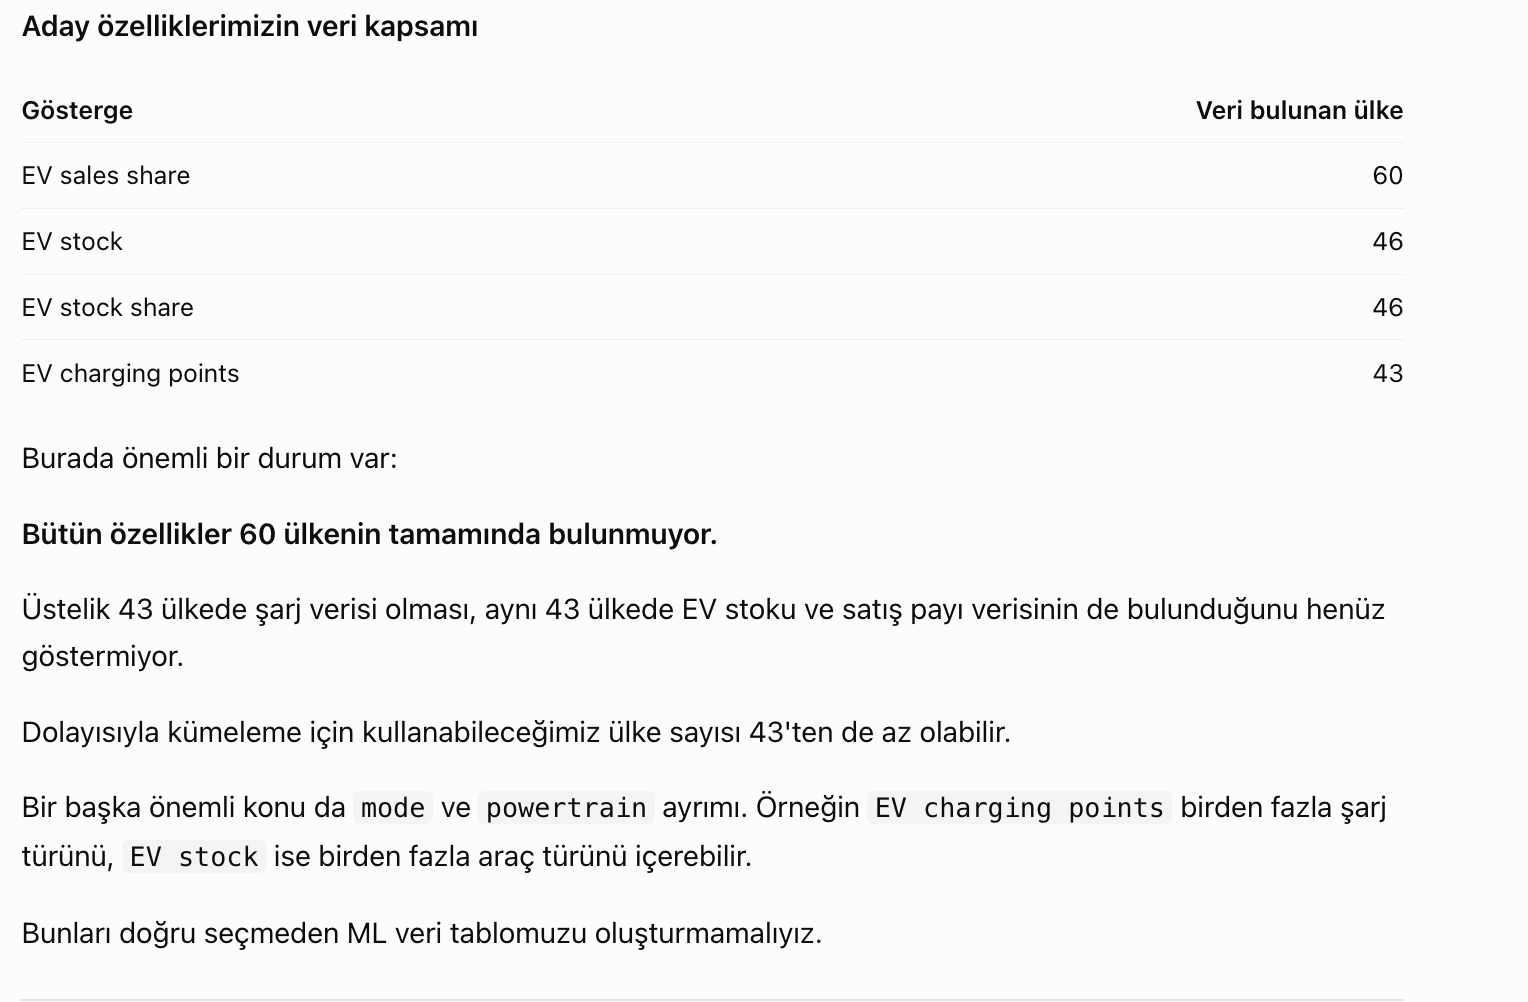

In [4]:
# EV stock için Cars ve EV kombinasyonunda kaç ülke var?

# EV sales share için hangi powertrain türleri mevcut?

# EV charging points için halka açık slow, fast ve ultra-fast kategorilerinin her birinde kaç ülke var?

# Aynı kombinasyonda beklenmeyen tekrar kayıtları bulunuyor mu?


# Kümeleme için değerlendirdiğimiz göstergeler
selected_parameters = [
    "EV sales share",
    "EV stock",
    "EV stock share",
    "EV charging points"
]

# Otomobil pazarı ve şarj altyapısı kayıtları
selected_data = df_2025[
    df_2025["parameter"].isin(selected_parameters)
    & df_2025["mode"].isin(["Cars", "EVSE"])
].copy()

# Her parameter-mode-powertrain kombinasyonunun kapsamı
combination_summary = (
    selected_data
    .groupby(
        ["parameter", "mode", "powertrain"],
        dropna=False
    )
    .agg(
        country_count=("region_country", "nunique"),
        record_count=("region_country", "size")
    )
    .reset_index()
    .sort_values(
        ["parameter", "country_count"],
        ascending=[True, False]
    )
)

display(combination_summary)


,parameter,mode,powertrain,country_count,record_count
1,EV charging points,EVSE,Publicly available slow,43,43
0,EV charging points,EVSE,Publicly available fast,41,41
2,EV charging points,EVSE,Publicly available ultra-fast,33,33
3,EV sales share,Cars,EV,60,60
4,EV stock,Cars,BEV,46,46
5,EV stock,Cars,EV,46,46
7,EV stock,Cars,PHEV,45,45
6,EV stock,Cars,FCEV,30,30
8,EV stock share,Cars,EV,46,46


In [5]:

# 2025 verilerindeki ülke gruplarını kontrol et
print("Aggregate group dağılımı:")

display(
    df_2025.groupby("Aggregate group")["region_country"]
    .nunique()
    .reset_index(name="country_count")
)

# Filtrelenmiş ülke isimlerini listele
countries = sorted(df_2025["region_country"].unique())

print("\nToplam benzersiz isim:", len(countries))

for i, country in enumerate(countries, start=1):
    print(f"{i:2}. {country}")


Aggregate group dağılımı:


,Aggregate group,country_count
0,Other,55
1,Projection_country,5



Toplam benzersiz isim: 60
 1. Australia
 2. Austria
 3. Belgium
 4. Brazil
 5. Bulgaria
 6. Cambodia
 7. Canada
 8. Chile
 9. China
10. Colombia
11. Costa Rica
12. Croatia
13. Cyprus
14. Czech Republic
15. Denmark
16. Estonia
17. Finland
18. France
19. Germany
20. Greece
21. Hungary
22. Iceland
23. India
24. Indonesia
25. Ireland
26. Israel
27. Italy
28. Japan
29. Jordan
30. Korea
31. Lao PDR
32. Latvia
33. Lithuania
34. Luxembourg
35. Malaysia
36. Mexico
37. Nepal
38. Netherlands
39. New Zealand
40. Norway
41. Philippines
42. Poland
43. Portugal
44. Romania
45. Russia
46. Singapore
47. Slovakia
48. Slovenia
49. South Africa
50. Spain
51. Sweden
52. Switzerland
53. Thailand
54. Turkiye
55. USA
56. United Arab Emirates
57. United Kingdom
58. Uruguay
59. Uzbekistan
60. Viet Nam


In [6]:
# Adım 3.5 — Ortak veriye sahip ülkeleri belirleme
# Kümeleme için seçtiğimiz özelliklerin tamamı kaç ülkede birlikte bulunuyor?


# Her özelliğin bulunduğu ülkeleri belirleyelim

def get_countries(parameter, mode, powertrain):
    filtered = df_2025[
        (df_2025["parameter"] == parameter) &
        (df_2025["mode"] == mode) &
        (df_2025["powertrain"] == powertrain) &
        (df_2025["value"].notna())
    ]
    return set(filtered["region_country"])


feature_countries = {
    "EV Sales Share": get_countries("EV sales share", "Cars", "EV"),
    "EV Stock": get_countries("EV stock", "Cars", "EV"),
    "EV Stock Share": get_countries("EV stock share", "Cars", "EV"),
    "Public Slow": get_countries(
        "EV charging points", "EVSE", "Publicly available slow"
    ),
    "Public Fast": get_countries(
        "EV charging points", "EVSE", "Publicly available fast"
    ),
    "Public Ultra-fast": get_countries(
        "EV charging points", "EVSE", "Publicly available ultra-fast"
    )
}

# Bütün özellikleri bulunan ülkeler
common_countries = set.intersection(*feature_countries.values())

print("Tüm özellikleri bulunan ülke sayısı:", len(common_countries))

print("\nOrtak ülkeler:")
for country in sorted(common_countries):
    print(country)


Tüm özellikleri bulunan ülke sayısı: 33

Ortak ülkeler:
Australia
Austria
Belgium
Canada
Chile
China
Denmark
Finland
France
Germany
Greece
Iceland
India
Indonesia
Israel
Italy
Jordan
Korea
Mexico
Netherlands
New Zealand
Norway
Poland
Portugal
Russia
Singapore
South Africa
Spain
Sweden
Switzerland
Turkiye
USA
United Kingdom


In [7]:

# EV pazarına ait üç temel gösterge
core_countries = (
    feature_countries["EV Sales Share"]
    & feature_countries["EV Stock"]
    & feature_countries["EV Stock Share"]
)

# Şarj kategorilerini aşamalı ekleyelim
with_slow = (
    core_countries
    & feature_countries["Public Slow"]
)

with_slow_fast = (
    with_slow
    & feature_countries["Public Fast"]
)

with_all_chargers = (
    with_slow_fast
    & feature_countries["Public Ultra-fast"]
)

print("Üç temel EV göstergesi:", len(core_countries))
print("+ Public Slow:", len(with_slow))
print("+ Public Fast:", len(with_slow_fast))
print("+ Public Ultra-fast:", len(with_all_chargers))

print("\nYalnızca ultra-fast eksik olduğu için dışlanan ülkeler:")
print(sorted(with_slow_fast - with_all_chargers))


Üç temel EV göstergesi: 46
+ Public Slow: 43
+ Public Fast: 41
+ Public Ultra-fast: 33

Yalnızca ultra-fast eksik olduğu için dışlanan ülkeler:
['Brazil', 'Colombia', 'Costa Rica', 'Japan', 'Malaysia', 'Philippines', 'Thailand', 'Viet Nam']


In [8]:

# Ultra-fast verisi olmadığı için dışlanan ülkeler
excluded_countries = sorted(
    with_slow_fast - with_all_chargers
)

charging_types = [
    "Publicly available slow",
    "Publicly available fast",
    "Publicly available ultra-fast"
]

# Bu ülkelerin şarj altyapısı kayıtları
charging_data = df_2025[
    (df_2025["region_country"].isin(excluded_countries)) &
    (df_2025["parameter"] == "EV charging points") &
    (df_2025["mode"] == "EVSE") &
    (df_2025["powertrain"].isin(charging_types))
]

# Ülkeleri satır, şarj türlerini sütun yap
charging_comparison = charging_data.pivot(
    index="region_country",
    columns="powertrain",
    values="value"
)

charging_comparison = charging_comparison.reindex(
    index=excluded_countries,
    columns=charging_types
)

display(charging_comparison)


powertrain,Publicly available slow,Publicly available fast,Publicly available ultra-fast
region_country,,,
Brazil,13000.0,3900.0,NaN
Colombia,1200.0,130.0,NaN
Costa Rica,1300.0,440.0,NaN
Japan,28000.0,11000.0,NaN
Malaysia,3700.0,2000.0,NaN
Philippines,180.0,94.0,NaN
Thailand,5100.0,6800.0,NaN
Viet Nam,21000.0,11000.0,NaN


In [ ]:

# Her yıl için tüm göstergeleri bulunan ülke sayısı
#Henüz yöntem değiştirmeyelim. Önce 2020–2025 arasında her yıl, 
#belirlediğimiz altı temel göstergesi eksiksiz olan kaç ülke bulunduğunu görelim.
required_combinations = [
    ("EV sales share", "Cars", "EV"),
    ("EV stock", "Cars", "EV"),
    ("EV stock share", "Cars", "EV"),
    ("EV charging points", "EVSE", "Publicly available slow"),
    ("EV charging points", "EVSE", "Publicly available fast"),
    ("EV charging points", "EVSE", "Publicly available ultra-fast"),
]

results = []

for year in range(2020, 2026):
    yearly_data = df[
        (df["category"] == "Historical") &
        (df["year"] == year) &
        (df["Aggregate group"].isin(["Other", "Projection_country"])) &
        (df["value"].notna())
    ]

    country_sets = []

    for parameter, mode, powertrain in required_combinations:
        countries = set(
            yearly_data.loc[
                (yearly_data["parameter"] == parameter) &
                (yearly_data["mode"] == mode) &
                (yearly_data["powertrain"] == powertrain),
                "region_country"
            ]
        )
        country_sets.append(countries)

    common = set.intersection(*country_sets)

    results.append({
        "Year": year,
        "Countries with complete data": len(common)
    })

yearly_coverage = pd.DataFrame(results)
display(yearly_coverage)


,Year,Countries with complete data
0,2020,24
1,2021,31
2,2022,32
3,2023,32
4,2024,33
5,2025,33


In [10]:

# Her yıl tüm göstergeleri bulunan ülkeleri belirle
countries_by_year = {}

for year in range(2020, 2026):
    yearly_data = df[
        (df["category"] == "Historical") &
        (df["year"] == year) &
        (df["Aggregate group"].isin(
            ["Other", "Projection_country"]
        )) &
        (df["value"].notna())
    ]

    country_sets = []

    for parameter, mode, powertrain in required_combinations:
        countries = set(
            yearly_data.loc[
                (yearly_data["parameter"] == parameter) &
                (yearly_data["mode"] == mode) &
                (yearly_data["powertrain"] == powertrain),
                "region_country"
            ]
        )
        country_sets.append(countries)

    countries_by_year[year] = set.intersection(*country_sets)

# 2020-2025 yıllarının tamamında bulunan ülkeler
all_years_countries = set.intersection(
    *countries_by_year.values()
)

print("6 yılın tamamında verisi bulunan ülke sayısı:",
      len(all_years_countries))

print("\nBu ülkeler:")
for country in sorted(all_years_countries):
    print(country)

# En az bir yılda bulunan ülkelerin toplamı
all_countries = set.union(*countries_by_year.values())

print("\nEn az bir yılda verisi bulunan ülke sayısı:",
      len(all_countries))


6 yılın tamamında verisi bulunan ülke sayısı: 23

Bu ülkeler:
Austria
Belgium
Canada
Chile
China
Denmark
Finland
France
Germany
Iceland
Italy
Mexico
Netherlands
New Zealand
Norway
Poland
Portugal
South Africa
Spain
Sweden
Switzerland
USA
United Kingdom

En az bir yılda verisi bulunan ülke sayısı: 33


In [11]:

# 2025 yılında eksiksiz verisi bulunan ülkeler
countries_2025 = sorted(countries_by_year[2025])

# Her ülkenin kaç yılda eksiksiz verisi olduğunu hesapla
coverage = pd.DataFrame({
    "country": countries_2025,
    "available_years": [
        sum(
            country in countries_by_year[year]
            for year in range(2020, 2026)
        )
        for country in countries_2025
    ]
})

print("Ülkelerin veri bulunan yıl sayıları:")
display(
    coverage["available_years"]
    .value_counts()
    .sort_index()
    .rename_axis("year_count")
    .reset_index(name="country_count")
)

print("\n6 yıldan az verisi bulunan ülkeler:")
display(coverage[coverage["available_years"] < 6])


Ülkelerin veri bulunan yıl sayıları:


,year_count,country_count
0,2,1
1,5,9
2,6,23



6 yıldan az verisi bulunan ülkeler:


,country,available_years
0,Australia,5
10,Greece,5
12,India,5
13,Indonesia,5
14,Israel,5
16,Jordan,5
17,Korea,5
24,Russia,5
25,Singapore,2
30,Turkiye,5


In [12]:

# 6 göstergenin ML sütun isimleri
feature_map = {
    ("EV sales share", "Cars", "EV"): "ev_sales_share",
    ("EV stock", "Cars", "EV"): "ev_stock",
    ("EV stock share", "Cars", "EV"): "ev_stock_share",
    ("EV charging points", "EVSE", "Publicly available slow"): "public_slow",
    ("EV charging points", "EVSE", "Publicly available fast"): "public_fast",
    ("EV charging points", "EVSE", "Publicly available ultra-fast"): "public_ultra_fast"
}

# 2020-2025 arasındaki gerçek ülke kayıtları
ml_data = df[
    (df["category"] == "Historical") &
    (df["year"].between(2020, 2025)) &
    (df["Aggregate group"].isin(["Other", "Projection_country"]))
].copy()

# Her kaydın hangi ML özelliğine karşılık geldiğini belirle
ml_data["feature"] = [
    feature_map.get((p, m, t))
    for p, m, t in zip(
        ml_data["parameter"],
        ml_data["mode"],
        ml_data["powertrain"]
    )
]

ml_data = ml_data.dropna(subset=["feature"])

# Aynı ülke-yıl-özellik için tekrar kaydı var mı?
duplicates = ml_data.duplicated(
    subset=["region_country", "year", "feature"]
).sum()

print("Tekrarlanan kayıt sayısı:", duplicates)

if duplicates:
    raise ValueError("Tekrarlanan kayıtlar incelenmeli.")

# Long -> Wide dönüşümü
ml_table = ml_data.pivot(
    index=["region_country", "year"],
    columns="feature",
    values="value"
)

# Yalnızca 6 özelliği de bulunan gözlemler
ml_table = ml_table.dropna().reset_index()
ml_table.columns.name = None

print("ML tablosunun boyutu:", ml_table.shape)
print("Benzersiz ülke:", ml_table["region_country"].nunique())

display(ml_table.head())


Tekrarlanan kayıt sayısı: 0
ML tablosunun boyutu: (185, 8)
Benzersiz ülke: 33


,region_country,year,ev_sales_share,ev_stock,ev_stock_share,public_fast,public_slow,public_ultra_fast
0,Australia,2021,2.7,48000.0,0.32,530.0,2000.0,250.0
1,Australia,2022,5.1,88000.0,0.59,780.0,2100.0,390.0
2,Australia,2023,11.0,190000.0,1.20,2100.0,5800.0,530.0
3,Australia,2024,12.0,300000.0,1.90,3100.0,5100.0,710.0
4,Australia,2025,15.0,430000.0,3.00,3900.0,5900.0,1300.0


In [13]:

# Kümeleme için aday sayısal özellikler
features = [
    "ev_sales_share",
    "ev_stock",
    "ev_stock_share",
    "public_slow",
    "public_fast",
    "public_ultra_fast"
]

# İstatistiksel özet
display(ml_table[features].describe().T)

# Eksik, sıfır ve negatif değer kontrolleri
quality_summary = pd.DataFrame({
    "missing": ml_table[features].isna().sum(),
    "zero": (ml_table[features] == 0).sum(),
    "negative": (ml_table[features] < 0).sum()
})

print("Veri kalitesi:")
display(quality_summary)

# Yüzde özelliklerinin geçerli aralık kontrolü
for feature in ["ev_sales_share", "ev_stock_share"]:
    invalid = (~ml_table[feature].between(0, 100)).sum()
    print(f"{feature} - 0-100 dışında: {invalid}")


,count,mean,std,min,25%,50%,75%,max
ev_sales_share,185.0,2.149052e+01,2.132325e+01,0.088,6.6,14.0,30.0,97.0
ev_stock,185.0,1.151273e+06,4.435098e+06,840.000,50000.0,210000.0,580000.0,44000000.0
ev_stock_share,185.0,4.397595e+00,6.310761e+00,0.015,0.6,2.0,5.3,36.0
public_slow,185.0,7.004818e+04,2.566526e+05,54.000,2200.0,9300.0,39000.0,2500000.0
public_fast,185.0,2.731853e+04,1.493022e+05,5.000,450.0,1500.0,4400.0,1400000.0
public_ultra_fast,185.0,1.172854e+04,6.681409e+04,1.000,120.0,630.0,3400.0,780000.0


Veri kalitesi:


,missing,zero,negative
ev_sales_share,0,0,0
ev_stock,0,0,0
ev_stock_share,0,0,0
public_slow,0,0,0
public_fast,0,0,0
public_ultra_fast,0,0,0


ev_sales_share - 0-100 dışında: 0
ev_stock_share - 0-100 dışında: 0


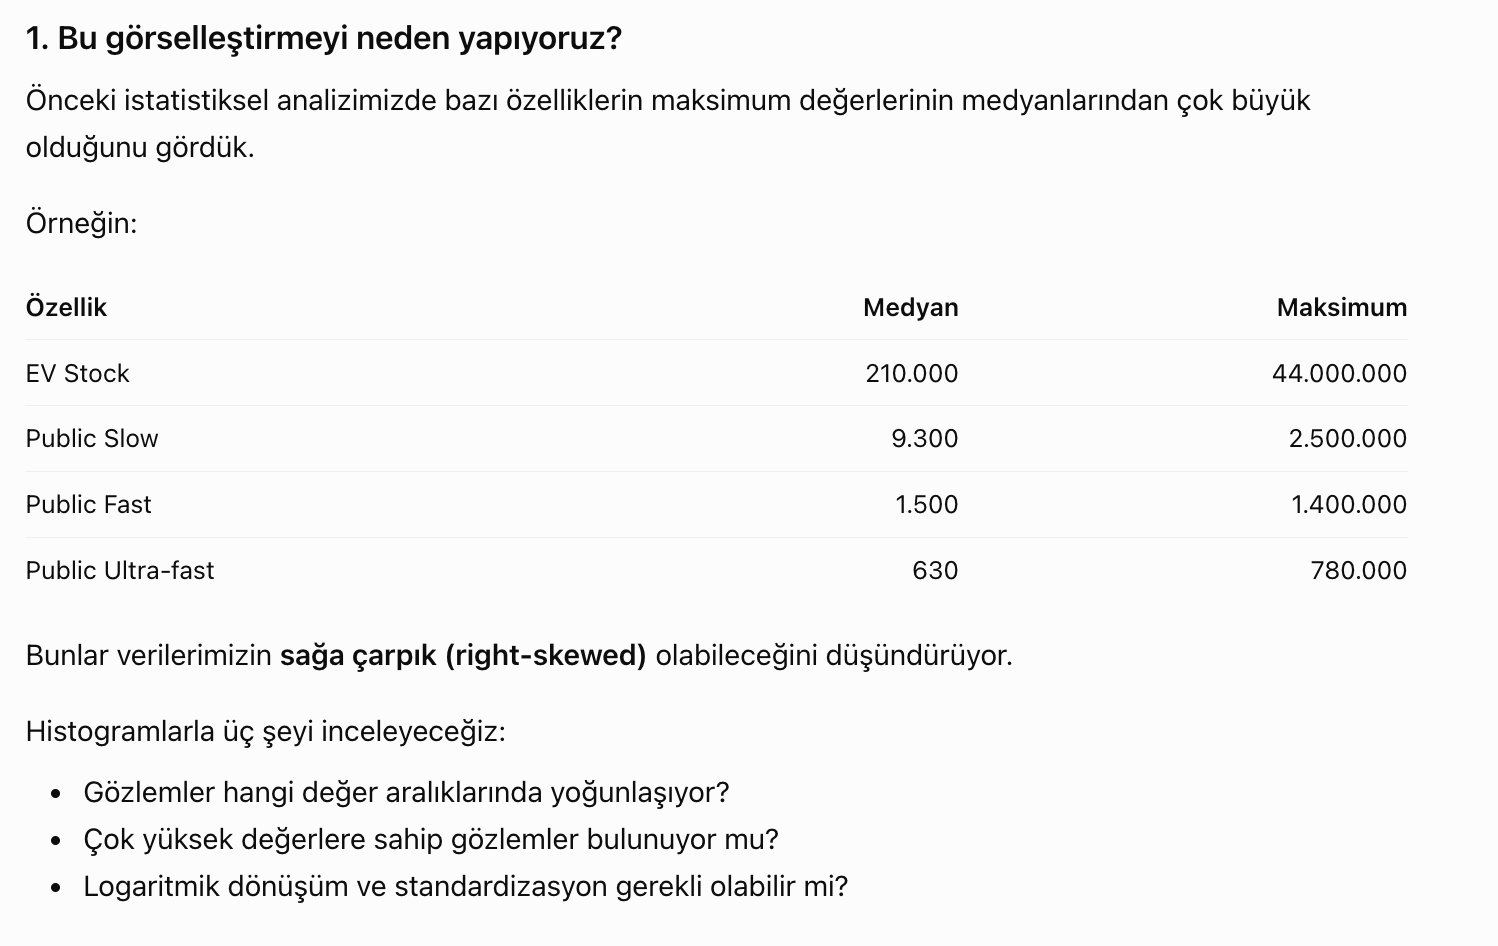

## 5. Exploratory Data Analysis (EDA)

### 5.1. Feature Distribution Analysis

Bu aşamada, kümeleme için belirlenen altı sayısal özelliğin
istatistiksel dağılımları histogramlar aracılığıyla incelenmektedir.

**Amaçlar:**

- Özelliklerin dağılım yapılarını incelemek.
- Çarpıklık (skewness) ve olası uç değerleri belirlemek.
- Özellikler arasındaki ölçek farklılıklarını değerlendirmek.
- Logaritmik dönüşüm ve standardizasyon gereksinimini belirlemek.

Bu analiz, K-Means ve diğer uzaklık temelli kümeleme
algoritmalarına uygun veri hazırlama yöntemlerini
seçmemize yardımcı olacaktır.

**Analiz kapsamı:** 2020–2025 dönemine ait 185 ülke-yıl
gözlemi ve 33 benzersiz ülke.

In [15]:
! pip install matplotlib

  Using cached matplotlib-3.11.2-cp312-cp312-macosx_11_0_arm64.whl.metadata (80 kB)
  Using cached contourpy-1.4.0-cp312-cp312-macosx_11_0_arm64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached kiwisolver-1.5.1-cp312-cp312-macosx_11_0_arm64.whl.metadata (5.2 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached matplotlib-3.11.2-cp312-cp312-macosx_11_0_arm64.whl (9.3 MB)
Using cached contourpy-1.4.0-cp312-cp312-macosx_11_0_arm64.whl (284 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 1.3 MB/s eta 0:00:00a 0:00:01
Using cached kiwisolver-1.5.1-cp312-cp312-macosx_11_0_arm64.whl (64 kB)
Using cached pyparsing-3.3.3-py3-none-any.whl (126 kB)

[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


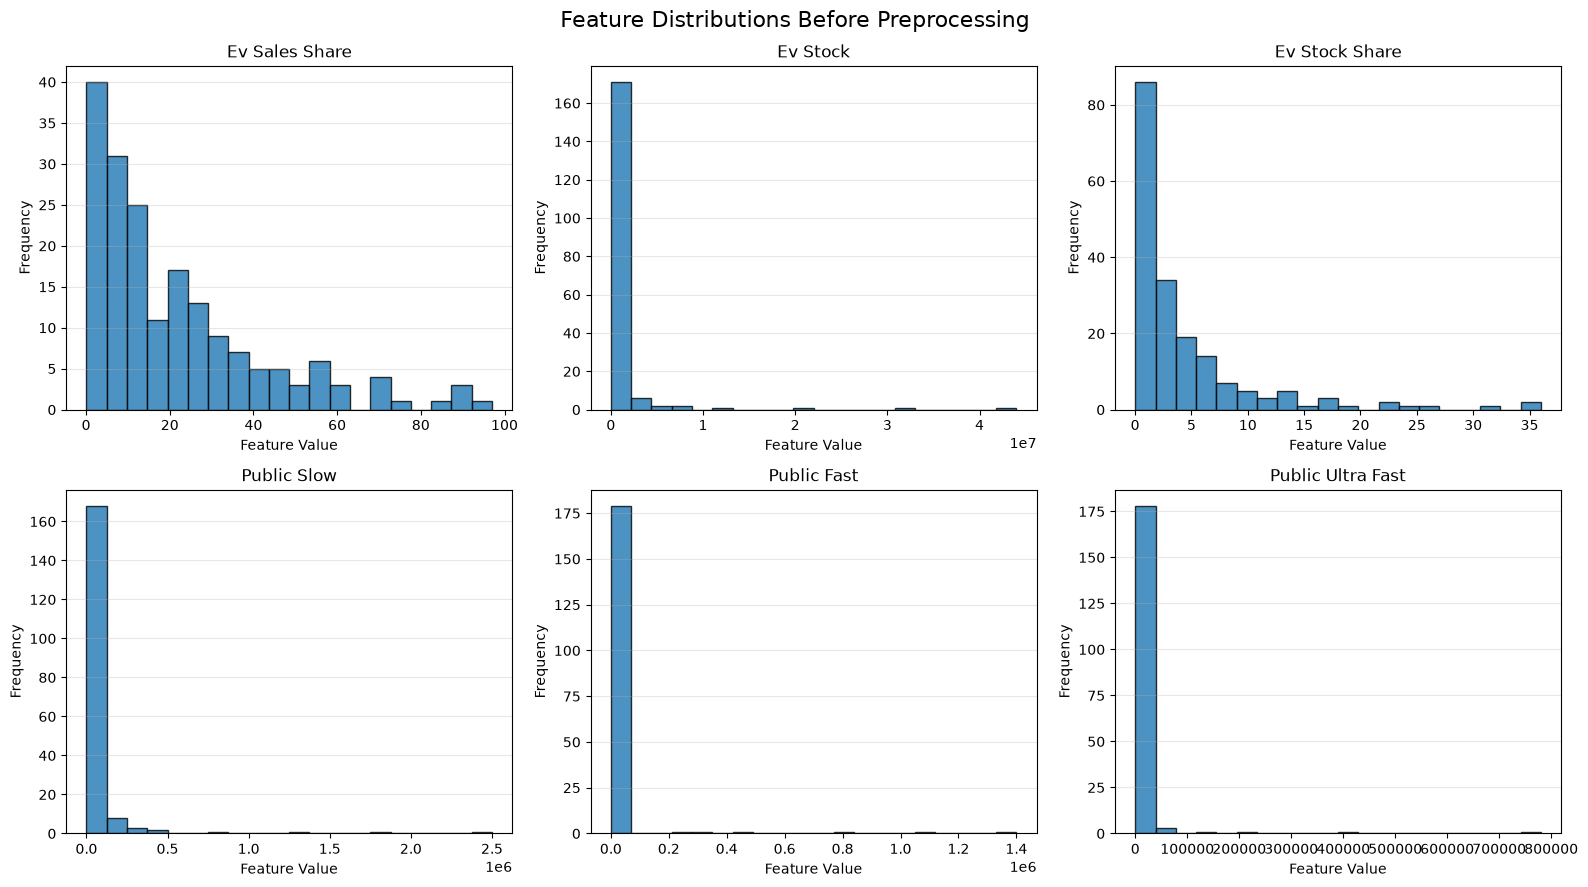

In [18]:

import matplotlib.pyplot as plt

# Kümeleme için belirlediğimiz altı özellik
features = [
    "ev_sales_share",
    "ev_stock",
    "ev_stock_share",
    "public_slow",
    "public_fast",
    "public_ultra_fast"
]

# 2 satır x 3 sütun şeklinde histogramlar
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, feature in zip(axes.flat, features):

    ax.hist(
        ml_table[feature],
        bins=20,
        edgecolor="black",
        alpha=0.8
    )

    ax.set_title(feature.replace("_", " ").title())
    ax.set_xlabel("Feature Value")
    ax.set_ylabel("Frequency")
    ax.grid(axis="y", alpha=0.3)

fig.suptitle(
    "Feature Distributions Before Preprocessing",
    fontsize=16
)

plt.tight_layout()
plt.show()


### 5.2. Feature Distribution Analysis — Findings

Altı aday özelliğin histogramları incelendiğinde aşağıdaki bulgular elde edilmiştir:

1. **EV Sales Share:** Dağılım sağa çarpıktır. Gözlemler çoğunlukla düşük ve orta satış paylarında yoğunlaşırken oldukça yüksek satış paylarına sahip gözlemler de bulunmaktadır.

2. **EV Stock:** Belirgin bir sağa çarpıklık gözlenmektedir. Az sayıda ülke-yıl gözleminin çok yüksek EV stokuna sahip olması dağılımın geniş bir aralığa yayılmasına neden olmaktadır.

3. **EV Stock Share:** Gözlemlerin büyük bölümü düşük stok paylarında yoğunlaşmaktadır. Yüksek elektrikleşme oranlarına sahip gözlemler sağ kuyrukta yer almaktadır.

4. **Public Charging Points:** Slow, fast ve ultra-fast şarj noktası göstergelerinin tamamında çok belirgin sağa çarpıklık bulunmaktadır. Bu özelliklerdeki büyük değer farklılıkları uzaklık temelli kümeleme algoritmalarını etkileyebilir.

**Genel değerlendirme:**

- Sayısal özelliklerin ölçekleri arasında ciddi farklılıklar bulunmaktadır.
- Özellikle EV Stock ve şarj noktası sayılarında logaritmik dönüşüm değerlendirilmelidir.
- Model eğitiminden önce uygun ölçeklendirme uygulanmalıdır.
- Yüksek değerler doğrudan veri hatası kabul edilmemeli, gerçek gözlemler olarak incelenmelidir.
- Analiz, 33 ülkeye ait 185 ülke-yıl gözlemiyle sınırlıdır.

**Sonraki adım:** Sayısal büyüklük göstergelerine logaritmik dönüşüm uygulanarak dağılımların önceki durumlarıyla karşılaştırılması.

3. Sıradaki adım — Log Transformation
Logaritmik dönüşüm, büyük değerler arasındaki farkları sıkıştırarak sağa çarpık dağılımları daha dengeli hâle getirmeye yardımcı olabilir.

Örneğin 100, 1.000 ve 1.000.000 değerleri arasındaki çok büyük sayısal uzaklıklar logaritmik ölçekte azalır.

Şimdilik sadece dört sayısal büyüklük göstergesini dönüştürmeyi deneyeceğiz:
- ev_stock
- public_slow
- public_fast
- public_ultra_fast
Yüzde özelliklerine bu aşamada dokunmayacağız

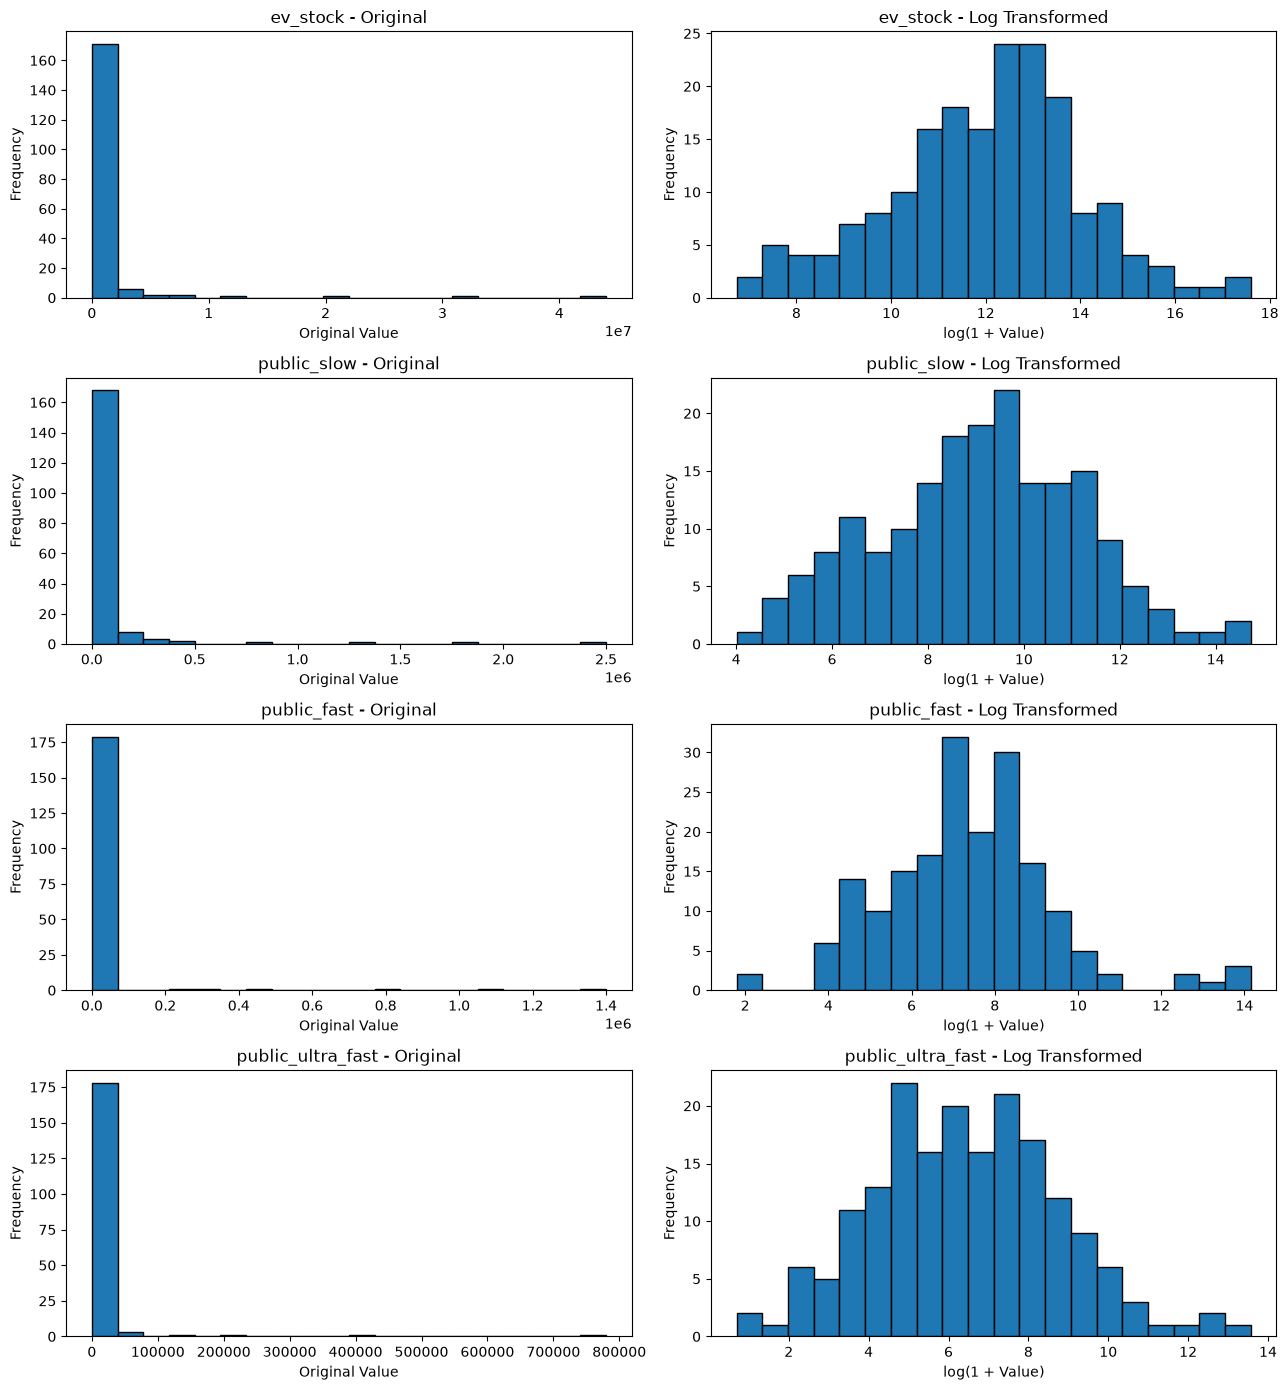

In [19]:

import numpy as np
import matplotlib.pyplot as plt

count_features = [
    "ev_stock",
    "public_slow",
    "public_fast",
    "public_ultra_fast"
]

fig, axes = plt.subplots(4, 2, figsize=(13, 14))

for i, feature in enumerate(count_features):
    original = ml_table[feature]
    transformed = np.log1p(original)

    # Original distribution
    axes[i, 0].hist(original, bins=20, edgecolor="black")
    axes[i, 0].set_title(f"{feature} - Original")
    axes[i, 0].set_xlabel("Original Value")
    axes[i, 0].set_ylabel("Frequency")

    # Log-transformed distribution
    axes[i, 1].hist(transformed, bins=20, edgecolor="black")
    axes[i, 1].set_title(f"{feature} - Log Transformed")
    axes[i, 1].set_xlabel("log(1 + Value)")
    axes[i, 1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()


### 5.3. Logarithmic Transformation — Findings

EV Stock, Public Slow, Public Fast ve Public Ultra-fast özelliklerine `log(1+x)` dönüşümü uygulanarak dağılımlar karşılaştırılmıştır.

**Gözlemler:**

1. Orijinal dağılımlarda gözlemler düşük değer aralıklarında yoğunlaşırken az sayıda çok yüksek değer bulunmaktadır.
2. Logaritmik dönüşüm sonrasında yüksek değerlerin etkisi azalmış ve gözlemlerin dağılımı daha belirgin hâle gelmiştir.
3. Dört özellikte de dönüşüm sonrasında dağılımlar daha dengeli görünmektedir. Bununla birlikte tamamen normal dağılım elde edildiği söylenemez.
4. Logaritmik dönüşüm, özellikle EV stoku ve şarj altyapısı büyüklükleri arasındaki çok büyük sayısal farklılıkları azaltmak açısından uygun bir adaydır.

**Ön değerlendirme:**

- EV Stock, Public Slow, Public Fast ve Public Ultra-fast özellikleri için logaritmik dönüşüm kullanılabilir.
- EV Sales Share ve EV Stock Share yüzde değişkenleri olduğundan bu aşamada dönüştürülmemiştir.
- Kümeleme öncesinde özellikler arasındaki ilişkiler incelenecek ve uygun ölçeklendirme uygulanacaktır.

**Sonuç:** Logaritmik dönüşüm, büyüklük göstergelerinin dağılımını daha dengeli hâle getirmiştir. Nihai özellik seçimi ve standardizasyon henüz tamamlanmamıştır.

In [20]:

import numpy as np
import pandas as pd

count_features = [
    "ev_stock",
    "public_slow",
    "public_fast",
    "public_ultra_fast"
]

skewness_comparison = pd.DataFrame({
    "Original Skewness": ml_table[count_features].skew(),
    "Log Skewness": np.log1p(
        ml_table[count_features]
    ).skew()
})

skewness_comparison["Improvement"] = (
    skewness_comparison["Original Skewness"].abs()
    - skewness_comparison["Log Skewness"].abs()
)

display(skewness_comparison.round(3))


,Original Skewness,Log Skewness,Improvement
ev_stock,7.443,-0.194,7.249
public_slow,7.147,-0.011,7.137
public_fast,7.318,0.541,6.777
public_ultra_fast,9.622,0.214,9.408


### 5.4. Skewness Analysis — Findings

Logaritmik dönüşümün etkisi, çarpıklık (skewness)
katsayıları kullanılarak sayısal olarak değerlendirilmiştir.

**Bulgular:**

- EV Stock: 7.443 → -0.194
- Public Slow: 7.147 → -0.011
- Public Fast: 7.318 → 0.541
- Public Ultra-fast: 9.622 → 0.214

Dört özelliğin tamamında çarpıklığın mutlak değeri
önemli ölçüde azalmıştır.

Bu sonuç, logaritmik dönüşümün EV stoku ve şarj
altyapısı büyüklüklerini modelleme öncesinde
dönüştürmek için uygun bir aday olduğunu göstermektedir.

Ancak logaritmik dönüşüm tek başına standardizasyon
sağlamaz. Özellikler arasındaki ilişkiler incelendikten
sonra nihai özellik seti ve ölçeklendirme yöntemi
belirlenecektir.

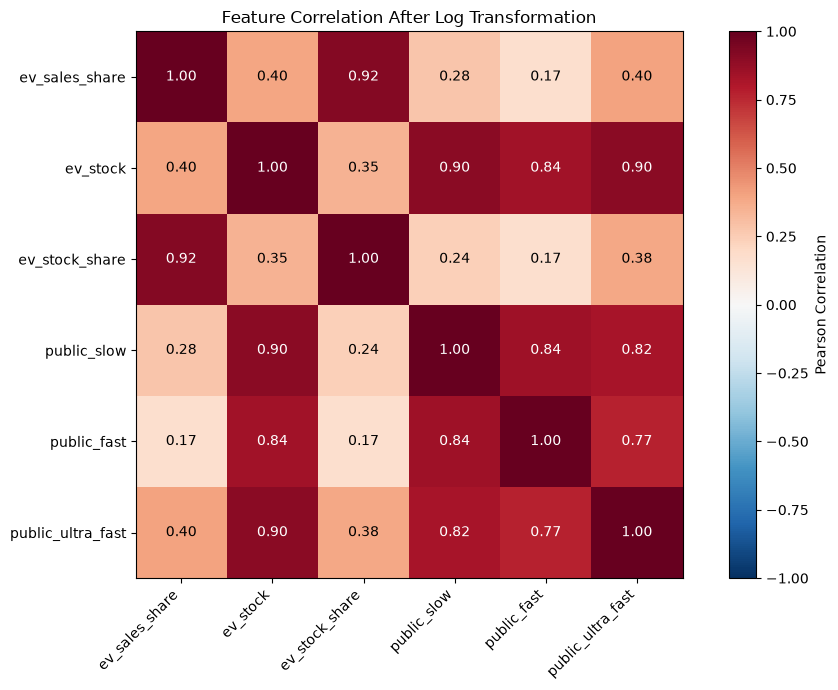

In [21]:

import numpy as np
import matplotlib.pyplot as plt

# Orijinal tabloyu değiştirmeden bir kopya oluştur
correlation_data = ml_table[features].copy()

# Sayısal büyüklük göstergelerine log dönüşümü
for feature in count_features:
    correlation_data[feature] = np.log1p(
        correlation_data[feature]
    )

# Pearson korelasyon matrisi
corr_matrix = correlation_data.corr(method="pearson")

# Korelasyon ısı haritası
fig, ax = plt.subplots(figsize=(10, 7))

im = ax.imshow(
    corr_matrix,
    cmap="RdBu_r",
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(features)))
ax.set_yticks(range(len(features)))

ax.set_xticklabels(features, rotation=45, ha="right")
ax.set_yticklabels(features)

# Korelasyon değerlerini hücrelerin içine yaz
for i in range(len(features)):
    for j in range(len(features)):
        value = corr_matrix.iloc[i, j]

        ax.text(
            j, i,
            f"{value:.2f}",
            ha="center",
            va="center",
            color="white" if abs(value) > 0.6 else "black"
        )

plt.colorbar(im, ax=ax, label="Pearson Correlation")
ax.set_title("Feature Correlation After Log Transformation")

plt.tight_layout()
plt.show()


### 5.5. Feature Correlation Analysis — Findings

Logaritmik dönüşüm sonrasında altı aday özellik arasındaki doğrusal ilişkiler Pearson korelasyon katsayısı kullanılarak incelenmiştir.

**Temel bulgular:**

1. EV Sales Share ile EV Stock Share arasında çok güçlü pozitif ilişki bulunmaktadır (r = 0.92). Bu iki gösterge farklı kavramları ölçmesine rağmen benzer EV benimseme eğilimlerini yansıtmaktadır.

2. EV Stock ile Public Slow ve Public Ultra-fast arasında çok güçlü pozitif ilişkiler bulunmaktadır (r = 0.90).

3. Şarj altyapısı göstergeleri de kendi aralarında güçlü pozitif korelasyonlar göstermektedir (r = 0.77–0.84).

4. EV Sales Share ve EV Stock Share göstergelerinin şarj noktası sayılarıyla ilişkileri görece daha zayıftır.

**Kümeleme açısından değerlendirme:**

Yüksek korelasyona sahip özelliklerin birlikte kullanılması, uzaklık temelli algoritmalarda belirli pazar boyutlarının gereğinden fazla temsil edilmesine neden olabilir.

Bu nedenle nihai özellik seti oluşturulurken EV benimseme düzeyi, pazar büyüklüğü ve şarj altyapısı boyutlarının dengeli temsil edilmesi hedeflenecektir.

Ayrıca analizde aynı ülkelerin farklı yıllara ait gözlemleri bulunduğundan, elde edilen korelasyonlar zaman içindeki ortak eğilimlerden etkilenebilir.

**Sonuç:** Özellikler arasında bilgi tekrarı olasılığı bulunmaktadır. Nihai özellik seçimi yapılmadan önce korelasyonların yıllar arasında tutarlı olup olmadığı incelenecektir.

In [22]:

# Yıllara göre önemli korelasyonları inceleyelim

pairs = [
    ("ev_sales_share", "ev_stock_share"),
    ("ev_stock", "public_slow"),
    ("ev_stock", "public_ultra_fast")
]

yearly_results = []

for year, group in ml_table.groupby("year"):
    row = {
        "year": year,
        "country_count": group["region_country"].nunique()
    }

    for feature_1, feature_2 in pairs:
        x = group[feature_1]
        y = group[feature_2]

        # Sayısal büyüklük özelliklerine log dönüşümü
        if feature_1 in count_features:
            x = np.log1p(x)

        if feature_2 in count_features:
            y = np.log1p(y)

        row[f"{feature_1} vs {feature_2}"] = x.corr(y)

    yearly_results.append(row)

yearly_corr = pd.DataFrame(yearly_results)

display(yearly_corr.round(3))


,year,country_count,ev_sales_share vs ev_stock_share,ev_stock vs public_slow,ev_stock vs public_ultra_fast
0,2020,24,0.937,0.917,0.931
1,2021,31,0.929,0.902,0.850
2,2022,32,0.939,0.894,0.896
3,2023,32,0.926,0.895,0.923
4,2024,33,0.924,0.901,0.904
5,2025,33,0.947,0.892,0.920


### 5.6. Yearly Correlation Analysis — Findings

Özellikler arasındaki yüksek korelasyonların yalnızca zaman içerisindeki ortak artış eğiliminden kaynaklanıp kaynaklanmadığını değerlendirmek amacıyla 2020–2025 yılları ayrı ayrı incelenmiştir.

**Bulgular:**

- EV Sales Share ile EV Stock Share arasındaki korelasyon her yıl 0.924–0.947 aralığındadır.
- EV Stock ile Public Slow arasındaki korelasyon her yıl 0.892–0.917 aralığındadır.
- EV Stock ile Public Ultra-fast arasındaki korelasyon her yıl 0.850–0.931 aralığındadır.

Bu sonuçlar, güçlü ilişkilerin yalnızca yılların bir arada değerlendirilmesinden kaynaklanmadığını göstermektedir. İlişkiler aynı yıl içerisindeki ülkeler arasında da gözlenmektedir.

**Kümeleme açısından değerlendirme:**

Mutlak EV stoku ve şarj noktası sayıları, ülkenin pazar büyüklüğünü birlikte yansıtıyor olabilir.

Bu nedenle kümeleme modelinde yalnızca mutlak büyüklükleri kullanmak yerine, şarj altyapısını EV stoku ile ilişkilendiren normalize edilmiş göstergelerin de değerlendirilmesi planlanmaktadır.

Analiz, her yıl farklı sayıda ülke içermektedir ve korelasyonlar nedensellik kanıtı olarak yorumlanmamalıdır.

In [23]:

# Orijinal ML tablomuzu koruyoruz
ml_features = ml_table.copy()

# 1.000 EV başına düşen şarj noktası sayısı
ml_features["slow_per_1000_evs"] = (
    ml_features["public_slow"]
    / ml_features["ev_stock"] * 1000
)

ml_features["fast_per_1000_evs"] = (
    ml_features["public_fast"]
    / ml_features["ev_stock"] * 1000
)

ml_features["ultra_fast_per_1000_evs"] = (
    ml_features["public_ultra_fast"]
    / ml_features["ev_stock"] * 1000
)

new_features = [
    "slow_per_1000_evs",
    "fast_per_1000_evs",
    "ultra_fast_per_1000_evs"
]

display(ml_features[new_features].describe().T)


,count,mean,std,min,25%,50%,75%,max
slow_per_1000_evs,185.0,82.655609,100.151374,2.230769,34.146341,52.380952,83.333333,596.774194
fast_per_1000_evs,185.0,20.304346,34.846532,0.526316,4.482759,7.636364,16.666667,284.615385
ultra_fast_per_1000_evs,185.0,5.647867,4.709473,0.139535,2.347826,4.431818,7.307692,21.555556


In [24]:

# Normalize edilmiş şarj altyapısı özellikleri
ratio_features = [
    "slow_per_1000_evs",
    "fast_per_1000_evs",
    "ultra_fast_per_1000_evs"
]

# Orijinal ve log dönüşümlü çarpıklık karşılaştırması
ratio_skewness = pd.DataFrame({
    "Original Skewness": ml_features[ratio_features].skew(),
    "Log Skewness": np.log1p(
        ml_features[ratio_features]
    ).skew()
})

display(ratio_skewness.round(3))


,Original Skewness,Log Skewness
slow_per_1000_evs,3.165,-0.013
fast_per_1000_evs,4.121,0.834
ultra_fast_per_1000_evs,1.455,-0.104


### 5.7. Normalized Charging Infrastructure — Skewness Analysis

Şarj altyapısı göstergeleri, her 1.000 elektrikli otomobile düşen şarj noktası sayısı olarak normalize edilmiştir.

Ardından üç yeni özelliğin dağılımındaki çarpıklık incelenmiştir.

**Bulgular:**

- Slow per 1,000 EVs: 3.165 → -0.013
- Fast per 1,000 EVs: 4.121 → 0.834
- Ultra-fast per 1,000 EVs: 1.455 → -0.104

Logaritmik dönüşüm, üç özellikte de çarpıklığın mutlak değerini azaltmıştır.

Bu göstergeler, ülkelerin şarj altyapısını yalnızca mutlak büyüklükleriyle değil, elektrikli otomobil stoklarına oranla değerlendirmemize olanak sağlamaktadır.

**Sonuç:** Normalize edilmiş şarj yoğunluğu özellikleri, kümeleme için anlamlı adaylardır. Ancak aynı EV stoku değerini payda olarak kullanmaları nedeniyle kendi aralarında yüksek korelasyon gösterebilirler.

Nihai özellik seçimi öncesinde bu ilişkilerin incelenmesi gerekmektedir.

In [25]:

# Kümeleme için değerlendirdiğimiz yeni özellik seti
candidate_features = [
    "ev_sales_share",
    "ev_stock_share",
    "ev_stock",
    "slow_per_1000_evs",
    "fast_per_1000_evs",
    "ultra_fast_per_1000_evs"
]

# Orijinal veriyi değiştirmeden kopyala
candidate_data = ml_features[candidate_features].copy()

# Büyüklük ve yoğunluk göstergelerine log dönüşümü
log_features = [
    "ev_stock",
    "slow_per_1000_evs",
    "fast_per_1000_evs",
    "ultra_fast_per_1000_evs"
]

for feature in log_features:
    candidate_data[feature] = np.log1p(
        candidate_data[feature]
    )

# Yeni özellikler arasındaki korelasyonlar
new_corr = candidate_data.corr(method="pearson")

display(new_corr.round(3))


,ev_sales_share,ev_stock_share,ev_stock,slow_per_1000_evs,fast_per_1000_evs,ultra_fast_per_1000_evs
ev_sales_share,1.000,0.919,0.398,-0.243,-0.428,0.119
ev_stock_share,0.919,1.000,0.351,-0.225,-0.334,0.185
ev_stock,0.398,0.351,1.000,-0.137,-0.356,0.075
slow_per_1000_evs,-0.243,-0.225,-0.137,1.000,0.428,0.076
fast_per_1000_evs,-0.428,-0.334,-0.356,0.428,1.000,0.086
ultra_fast_per_1000_evs,0.119,0.185,0.075,0.076,0.086,1.000


1. Başlangıçta hangi özelliklerimiz vardı?
185 ülke-yıl gözleminden oluşan veri tablomuzda şu 6 özellik bulunuyordu:
Özellik	Ne ifade ediyor?
ev_sales_share	Yeni otomobil satışlarındaki EV oranı (%)
ev_stock	Kullanımdaki elektrikli otomobil sayısı
ev_stock_share	Mevcut otomobil filosundaki EV oranı (%)
public_slow	Yavaş şarj noktası sayısı
public_fast	Hızlı şarj noktası sayısı
public_ultra_fast	Ultra hızlı şarj noktası sayısı

Bunların tamamı veri setinden aldığımız orijinal özelliklerdi.
2. Logaritmik dönüşümde ne yaptık?
Örneğin ev_stock değerlerinin 840 ile 44 milyon arasında değiştiğini gördük.

Bu büyük farkları azaltmak için:
\[
x_{\text{log}}=\ln(1+x)
\]

dönüşümünü denedik.

Burada önemli nokta şu:

Log dönüşümü yeni bir bilgi üretmez. Aynı özelliğin sayısal ölçeğini değiştirir.

Örneğin ev_stock ile log(ev_stock) aynı bilgiyi farklı biçimde temsil eder.

Dolayısıyla log dönüşümü yaptığımızda ülkelere ait yeni bir gösterge keşfetmiş olmadık.
3. Asıl yeni özellikleri ne zaman oluşturduk?
Korelasyon analizinde şunu fark ettik:
- EV Stock ile Public Slow arasında yüksek korelasyon vardı: 0.90
- EV Stock ile Public Ultra-fast arasında yüksek korelasyon vardı: 0.90
Büyük EV pazarlarında daha fazla şarj noktası bulunması mantıklıydı.

Ama biz şu soruyu da araştırmak istedik:

Bir ülkede EV sayısına oranla ne kadar şarj altyapısı bulunuyor?

İşte burada üç yeni özellik oluşturduk.
Yeni oluşturduğumuz 3 özellik
1. slow_per_1000_evs

Her 1.000 elektrikli otomobil başına düşen yavaş şarj noktası sayısı.
\[
\frac{\text{Public Slow}}{\text{EV Stock}}\times1000
\]



2. fast_per_1000_evs

Her 1.000 elektrikli otomobil başına düşen hızlı şarj noktası sayısı.
\[
\frac{\text{Public Fast}}{\text{EV Stock}}\times1000
\]



3. ultra_fast_per_1000_evs

Her 1.000 elektrikli otomobil başına düşen ultra hızlı şarj noktası sayısı.
\[
\frac{\text{Public Ultra-fast}}{\text{EV Stock}}\times1000
\]



Küçük bir örnek
Aşağıdaki değerler yalnızca hesaplamayı açıklamak içindir.
	Ülke A	Ülke B
EV Stock	1.000.000	100.000
Public Fast	50.000	10.000
1.000 EV başına Fast	50	100

Ülke A'nın daha fazla şarj noktası var. Ancak Ülke B'de elektrikli otomobil başına daha fazla şarj noktası düşüyor.

İşte yeni özelliklerimizin farkı bu: Mutlak altyapı büyüklüğü yerine EV stokuna göre altyapı yoğunluğunu ölçüyorlar. Bu oranlar tek başına altyapının yeterli olduğunu kanıtlamaz.
4. Peki neden yeni özelliklere de log uyguladık?
Çünkü oluşturduğumuz bu üç yeni oranın da dağılımlarının sağa çarpık olduğunu gördük.
Yeni özellik	Log öncesi çarpıklık	Log sonrası
Slow / 1.000 EV	3.165	-0.013
Fast / 1.000 EV	4.121	0.834
Ultra-fast / 1.000 EV	1.455	-0.104

Yani önce yeni özellik ürettik, ardından bu özelliklerin değerlerine log dönüşümü denedik.

Bunlar iki farklı işlemdir.


## 6. Feature Set Comparison

Kümeleme analizinde yüksek korelasyona sahip özelliklerin etkisini değerlendirmek amacıyla iki alternatif özellik seti oluşturulacaktır.

- **Feature Set A:** EV Sales Share, EV Stock ve üç şarj yoğunluğu göstergesi.
- **Feature Set B:** Feature Set A'ya ek olarak EV Stock Share.

Her iki özellik setine aynı ön işleme yaklaşımı uygulanacak ve K-Means, Agglomerative Clustering ve DBSCAN algoritmalarıyla deneyler gerçekleştirilecektir.

Karşılaştırmada küme ayrışması, küme profillerinin anlamlılığı ve özellik seçimine karşı sonuçların kararlılığı dikkate alınacaktır.

**Amaç:** EV Stock Share özelliğinin eklenmesinin kümeleme sonuçlarını nasıl değiştirdiğini belirlemek.


In [28]:
!pip install scikit-learn

  Using cached scikit_learn-1.9.1-cp312-cp312-macosx_12_0_arm64.whl.metadata (9.3 kB)
  Using cached scipy-1.18.1-cp312-cp312-macosx_14_0_arm64.whl.metadata (62 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached scikit_learn-1.9.1-cp312-cp312-macosx_12_0_arm64.whl (8.3 MB)
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached scipy-1.18.1-cp312-cp312-macosx_14_0_arm64.whl (20.5 MB)
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)

[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [29]:
from sklearn.preprocessing import StandardScaler
import pandas as pd

# Feature Set A
features_A = [
    "ev_sales_share",
    "ev_stock",
    "slow_per_1000_evs",
    "fast_per_1000_evs",
    "ultra_fast_per_1000_evs"
]

# Feature Set B
features_B = [
    "ev_sales_share",
    "ev_stock_share",
    "ev_stock",
    "slow_per_1000_evs",
    "fast_per_1000_evs",
    "ultra_fast_per_1000_evs"
]

# Log dönüşümleri uygulanmış veriler
X_A = candidate_data[features_A].copy()
X_B = candidate_data[features_B].copy()

# Her özellik setini ayrı ölçeklendir
scaler_A = StandardScaler()
scaler_B = StandardScaler()

X_A_scaled = pd.DataFrame(
    scaler_A.fit_transform(X_A),
    columns=features_A,
    index=X_A.index
)

X_B_scaled = pd.DataFrame(
    scaler_B.fit_transform(X_B),
    columns=features_B,
    index=X_B.index
)

print("Feature Set A:", X_A_scaled.shape)
print("Feature Set B:", X_B_scaled.shape)

print("\nFeature Set A - İlk 5 gözlem:")
display(X_A_scaled.head())

print("\nStandardizasyon kontrolü:")
display(pd.DataFrame({
    "Mean": X_A_scaled.mean(),
    "Std": X_A_scaled.std(ddof=0)
}).round(3))


Feature Set A: (185, 5)
Feature Set B: (185, 6)

Feature Set A - İlk 5 gözlem:


,ev_sales_share,ev_stock,slow_per_1000_evs,fast_per_1000_evs,ultra_fast_per_1000_evs
0,-0.883613,-0.606326,-0.292844,0.075991,0.236108
1,-0.770755,-0.306987,-0.903463,-0.119042,0.044278
2,-0.493311,0.073124,-0.635004,0.076880,-0.472626
3,-0.446286,0.298696,-1.268734,0.016729,-0.642469
4,-0.305213,0.476485,-1.496130,-0.098824,-0.386681



Standardizasyon kontrolü:


,Mean,Std
ev_sales_share,-0.0,1.0
ev_stock,-0.0,1.0
slow_per_1000_evs,0.0,1.0
fast_per_1000_evs,0.0,1.0
ultra_fast_per_1000_evs,-0.0,1.0


### 6.1. Feature Standardization — Results and Interpretation

Kümeleme algoritmalarında özellikler arasındaki sayısal ölçek farklılıklarının uzaklık hesaplamalarını etkilemesini önlemek amacıyla **StandardScaler** yöntemi uygulanmıştır.

StandardScaler, her özelliği ortalaması 0 ve standart sapması 1 olacak şekilde dönüştürür.

**Standardizasyon formülü:**

\[
z = \frac{x-\mu}{\sigma}
\]

Burada:

- \(x\): Özelliğin orijinal veya ön işlemden geçirilmiş değeri
- \(\mu\): Özelliğin ortalaması
- \(\sigma\): Özelliğin standart sapması
- \(z\): Standartlaştırılmış değer

#### Negatif ve Pozitif Değerlerin Yorumlanması

Standardizasyon sonrasında negatif değerler oluşması normaldir.

- **z = 0:** Gözlem, ilgili özelliğin ortalamasındadır.
- **z < 0:** Gözlem, ilgili özelliğin ortalamasının altındadır.
- **z > 0:** Gözlem, ilgili özelliğin ortalamasının üzerindedir.
- **z = -1:** Gözlem, ortalamanın bir standart sapma altındadır.
- **z = +1:** Gözlem, ortalamanın bir standart sapma üzerindedir.

Örneğin Avustralya'nın 2021 yılı gözleminde:

| Özellik | Standartlaştırılmış değer | Yorum |
|---|---:|---|
| EV Sales Share | -0.884 | Ortalamanın altında |
| EV Stock | -0.606 | Ortalamanın altında |
| Slow / 1,000 EVs | -0.293 | Ortalamanın biraz altında |
| Fast / 1,000 EVs | 0.076 | Ortalamaya yakın, biraz üzerinde |
| Ultra-fast / 1,000 EVs | 0.236 | Ortalamanın biraz üzerinde |

Negatif değerler, EV satış payının veya araç sayısının gerçekte negatif olduğu anlamına gelmemektedir. Yalnızca ilgili özelliğin, uygulanan dönüşümler sonrasında veri seti ortalamasının altında olduğunu göstermektedir.

#### Standardizasyon Sonuçları

İki alternatif özellik setine StandardScaler ayrı ayrı uygulanmıştır.

| Özellik seti | Gözlem sayısı | Özellik sayısı |
|---|---:|---:|
| Feature Set A | 185 | 5 |
| Feature Set B | 185 | 6 |

Standardizasyon sonrasında kontrol edilen özelliklerin:

- **Ortalaması (Mean):** Yaklaşık 0
- **Standart sapması (Std):** 1

olarak hesaplanmıştır.

Bu sonuçlar, standardizasyon işleminin beklendiği şekilde tamamlandığını göstermektedir.

#### Kümeleme Açısından Değerlendirme

Başlangıç veri setindeki EV Stock ve şarj noktası sayıları, EV satış payı gibi yüzde göstergelerinden çok daha büyük sayısal değerlere sahiptir.

Standardizasyon uygulanmadığında K-Means gibi uzaklık temelli algoritmalarda büyük ölçekli özellikler kümeleme sonuçlarını baskılayabilir.

StandardScaler ile özellikler karşılaştırılabilir ölçeklere getirilmiştir.

Ancak standardizasyon, özellikler arasındaki yüksek korelasyonları ortadan kaldırmaz. Bu nedenle beş özellikli **Feature Set A** ve altı özellikli **Feature Set B** ayrı ayrı değerlendirilecektir.

#### Sonuç

185 ülke-yıl gözleminden oluşan iki alternatif özellik seti başarıyla standartlaştırılmıştır.

Veri hazırlama aşamasında logaritmik dönüşüm ve standardizasyon uygulanmış, orijinal veri korunmuştur.

Bir sonraki aşamada **K-Means Clustering** algoritması kullanılarak farklı küme sayıları denenecek ve iki özellik setinin sonuçları karşılaştırılacaktır.

## Data Selection and Feature Extraction Methodology

### 1. Veri Seçiminin Amacı

Bu çalışmada ülkelerin elektrikli araç (EV) benimseme düzeyleri, pazar büyüklükleri ve şarj altyapısı özelliklerine göre kümelendirilmesi amaçlanmaktadır.

Orijinal IEA Global EV Outlook 2026 veri setindeki her satır, belirli bir coğrafya, yıl, gösterge, araç türü ve teknoloji kategorisine ait sayısal bir ölçümü temsil etmektedir.

Makine öğrenmesi için kullanılacak özellikleri oluştururken `parameter`, `mode` ve `powertrain` sütunları birlikte değerlendirilerek ilgili kayıtların `value` değerleri seçilmiştir.

### 2. Temel Veri Filtreleme Kriterleri

Kümeleme analizinde aşağıdaki koşullar uygulanmıştır:

| Sütun | Uygulanan filtre | Açıklama |
|---|---|---|
| `category` | Historical | Gerçek tarihsel gözlemler seçilmiştir. |
| `year` | 2020–2025 | Altı yıllık dönem incelenmiştir. |
| `Aggregate group` | Other, Projection_country | Yalnızca ülke düzeyindeki kayıtlar alınmıştır. |
| `region_country` | Ülke adı | Gözlemlerin hangi ülkeye ait olduğunu belirlemek için kullanılmıştır. |
| `value` | Sayısal ölçüm | Seçilen göstergenin değerini sağlamaktadır. |

`World` ve bölgesel toplamlar ülke gözlemi olarak değerlendirilmemiştir.

### 3. Parameter, Mode ve Powertrain Kombinasyonları

Özellik seçimi sırasında yalnızca `parameter` sütununa bakılmamıştır. Her göstergenin doğru araç türünü ve teknolojiyi temsil ettiğinden emin olmak için üç sütunun kombinasyonu kullanılmıştır.

#### 3.1. EV Pazarı Göstergeleri

| Oluşturulan özellik | parameter | mode | powertrain |
|---|---|---|---|
| `ev_sales_share` | EV sales share | Cars | EV |
| `ev_stock` | EV stock | Cars | EV |
| `ev_stock_share` | EV stock share | Cars | EV |

Bu üç özellikte:

- `mode = Cars`
- `powertrain = EV`

sabit tutulmuştur.

Özellikler arasındaki ayrım `parameter` sütunu üzerinden yapılmıştır.

Böylece otomobil dışındaki araç türlerinin stok ve satış payı değerlerinin analize yanlışlıkla dahil edilmesi önlenmiştir.

#### 3.2. Şarj Altyapısı Göstergeleri

| Oluşturulan özellik | parameter | mode | powertrain |
|---|---|---|---|
| `public_slow` | EV charging points | EVSE | Publicly available slow |
| `public_fast` | EV charging points | EVSE | Publicly available fast |
| `public_ultra_fast` | EV charging points | EVSE | Publicly available ultra-fast |

Bu üç özellikte:

- `parameter = EV charging points`
- `mode = EVSE`

sabit tutulmuştur.

Şarj türleri arasındaki ayrım `powertrain` sütununa göre yapılmıştır.

Slow, fast ve ultra-fast kategorileri veri setinde hazır olarak bulunmaktadır. Bu çalışmada şarj noktaları güç seviyelerine göre yeniden sınıflandırılmamıştır.

### 4. Value Sütununun Kullanımı

`parameter`, `mode` ve `powertrain` sütunları, hangi ölçümün seçileceğini belirlemek için kullanılmıştır.

Bu koşulları sağlayan her ülke-yıl kaydının sayısal değeri ise `value` sütunundan alınmıştır.

Örneğin:

- `EV stock + Cars + EV` kombinasyonunun `value` değeri → `ev_stock`
- `EV sales share + Cars + EV` kombinasyonunun `value` değeri → `ev_sales_share`
- `EV charging points + EVSE + Publicly available fast` kombinasyonunun `value` değeri → `public_fast`

Dolayısıyla `value` sütunundaki bütün değerler doğrudan birlikte kullanılmamış, ilgili gösterge kombinasyonlarına göre ayrıştırılmıştır.

### 5. Long Format'tan Wide Format'a Dönüşüm

Orijinal veri setinde farklı göstergeler ayrı satırlarda tutulmaktadır (*long format*).

Kümeleme algoritmalarında kullanılabilecek bir özellik tablosu oluşturmak amacıyla `pivot()` işlemi uygulanmıştır.

Dönüşümde:

- **Index:** `region_country`, `year`
- **Columns:** Oluşturulan özellik isimleri
- **Values:** `value`

olarak belirlenmiştir.

Böylece her satırın bir ülkenin belirli yıldaki EV pazarını temsil ettiği, her sütunun ise ayrı bir sayısal özelliği içerdiği tablo oluşturulmuştur.

Dönüşüm öncesinde aynı ülke-yıl-özellik kombinasyonuna ait tekrar eden kayıtlar kontrol edilmiş ve tekrarlanan kayıt sayısı **0** bulunmuştur.

### 6. Veri Kapsamı ve Eksik Değer Yönetimi

Başlangıçta 2025 yılı için bütün göstergeleri bulunan 33 ülke belirlenmiştir.

Daha fazla tarihsel gözlemden yararlanmak amacıyla analiz kapsamı 2020–2025 dönemine genişletilmiştir.

Altı temel göstergenin tamamı bulunan ülke-yıl gözlemleri seçilmiştir.

**Elde edilen veri tablosu:**

| Bilgi | Değer |
|---|---:|
| Analiz dönemi | 2020–2025 |
| Benzersiz ülke sayısı | 33 |
| Ülke-yıl gözlem sayısı | 185 |
| Başlangıç özellik sayısı | 6 |
| Tekrarlanan ülke-yıl-özellik kaydı | 0 |
| Seçilen tabloda eksik değer | 0 |

Eksik gösterge değerleri sıfır kabul edilmemiştir. Altı göstergenin tamamı bulunmayan ülke-yıl kayıtları başlangıç ML tablosuna dahil edilmemiştir.

### 7. Türetilmiş Şarj Altyapısı Özellikleri

İlk altı özellik oluşturulduktan sonra mutlak şarj noktası sayılarının EV stoku ile güçlü ilişkiler gösterdiği belirlenmiştir.

Ülkelerin şarj altyapısını pazar büyüklüğüne göre değerlendirebilmek amacıyla üç yeni özellik hesaplanmıştır:

| Yeni özellik | Hesaplama |
|---|---|
| `slow_per_1000_evs` | `public_slow / ev_stock × 1000` |
| `fast_per_1000_evs` | `public_fast / ev_stock × 1000` |
| `ultra_fast_per_1000_evs` | `public_ultra_fast / ev_stock × 1000` |

Bu özellikler, her 1.000 elektrikli otomobile düşen ilgili türdeki halka açık şarj noktası sayısını göstermektedir.

Türetilmiş özellikler orijinal CSV'de doğrudan bulunan göstergeler değildir; seçilmiş sayısal değerlerden hesaplanmıştır.

Bu oranlar şarj altyapısı yoğunluğunu yaklaşık olarak karşılaştırmak amacıyla kullanılır. Şarj altyapısının kapasitesini veya yeterliliğini tek başına kanıtlamaz.

### 8. Model Girişinde Kullanılan Özellik Setleri

Veri seçimi ve ön işleme analizlerinden sonra iki alternatif özellik seti hazırlanmıştır.

**Feature Set A — 5 Özellik**

- EV Sales Share
- EV Stock
- Slow per 1,000 EVs
- Fast per 1,000 EVs
- Ultra-fast per 1,000 EVs

**Feature Set B — 6 Özellik**

Feature Set A'daki beş özelliğe ek olarak:

- EV Stock Share

İki özellik seti, EV Sales Share ile EV Stock Share arasındaki yüksek korelasyonun kümeleme sonuçlarını nasıl etkilediğini değerlendirmek amacıyla oluşturulmuştur.

Sayısal büyüklük ve yoğunluk göstergelerine logaritmik dönüşüm uygulanmış, ardından iki özellik seti ayrı ayrı `StandardScaler` ile standartlaştırılmıştır.

`region_country` ve `year` sütunları modelin sayısal özellikleri arasında kullanılmamış, kümeleme sonuçlarının ülke ve yıl bazında yorumlanabilmesi için korunmuştur.

### 9. Sonuç

Bu veri hazırlama sürecinde:

1. Uygun ülke ve tarihsel yıl kayıtları seçilmiştir.
2. `parameter`, `mode` ve `powertrain` kombinasyonlarıyla doğru göstergeler belirlenmiştir.
3. Sayısal değerler `value` sütunundan alınmıştır.
4. Veri uzun formattan ülke-yıl bazlı geniş formata dönüştürülmüştür.
5. Eksik ve tekrarlanan kayıtlar kontrol edilmiştir.
6. Şarj altyapısını EV stokuna göre temsil eden yeni özellikler oluşturulmuştur.
7. İki alternatif özellik seti hazırlanmıştır.

**Sonuç olarak, 33 ülkeye ait 185 ülke-yıl gözleminden oluşan veri seti, K-Means ve diğer kümeleme algoritmalarıyla gerçekleştirilecek deneyler için hazırlanmıştır.**

Bu çalışma ülke-yıl EV pazar profillerini kümelendirmektedir; 185 gözlem, 185 bağımsız ülkeyi temsil etmemektedir.

In [ ]:

from pathlib import Path

# Proje klasöründeki clustering dizinini bul
output_dir = None

for folder in [Path.cwd(), *Path.cwd().parents]:
    candidate = folder / "data" / "modeldataset" / "clustering"
 
    if candidate.is_dir():
        output_dir = candidate
        break

if output_dir is None:
    raise FileNotFoundError("Clustering klasörü bulunamadı.")

# 1. Orijinal ve türetilmiş özellikleri sakla
ml_features.to_csv(
    output_dir / "clustering_dataset.csv",
    index=False
)

# 2. Standartlaştırılmış Feature Set A
feature_A_export = pd.concat(
    [
        ml_table[["region_country", "year"]],
        X_A_scaled
    ],
    axis=1
)

feature_A_export.to_csv(
    output_dir / "feature_set_A.csv",
    index=False
)

# 3. Standartlaştırılmış Feature Set B
feature_B_export = pd.concat(
    [
        ml_table[["region_country", "year"]],
        X_B_scaled
    ],
    axis=1
)

feature_B_export.to_csv(
    output_dir / "feature_set_B.csv",
    index=False
)

print("Dosyalar kaydedildi:")
for filename in [
    "clustering_dataset.csv",
    "feature_set_A.csv",
    "feature_set_B.csv"
]:
    print(output_dir / filename)


Dosyalar kaydedildi:
/Users/rabia/global-electric-vehicle-dashboard/global-electric-vehicle-dashboard/data/modeldataset/clustering/clustering_dataset.csv
/Users/rabia/global-electric-vehicle-dashboard/global-electric-vehicle-dashboard/data/modeldataset/clustering/feature_set_A.csv
/Users/rabia/global-electric-vehicle-dashboard/global-electric-vehicle-dashboard/data/modeldataset/clustering/feature_set_B.csv


### Adım 5.1 — K-Means modelini çalıştırma

In [31]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd

# Daha önce standartlaştırdığımız iki özellik seti
feature_sets = {
    "A": X_A_scaled,
    "B": X_B_scaled
}

results = []

for set_name, X_data in feature_sets.items():

    for k in range(2, 9):

        model = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=10
        )

        labels = model.fit_predict(X_data)

        cluster_sizes = pd.Series(labels).value_counts()

        results.append({
            "Feature Set": set_name,
            "k": k,
            "Silhouette Score": silhouette_score(X_data, labels),
            "Inertia": model.inertia_,
            "Min Cluster Size": cluster_sizes.min(),
            "Max Cluster Size": cluster_sizes.max()
        })

kmeans_results = pd.DataFrame(results)

display(kmeans_results.round(3))


,Feature Set,k,Silhouette Score,Inertia,Min Cluster Size,Max Cluster Size
0,A,2,0.313,670.199,44,141
1,A,3,0.224,539.632,42,74
2,A,4,0.222,468.006,28,66
3,A,5,0.238,403.569,19,66
4,A,6,0.226,361.181,14,44
5,A,7,0.255,327.884,5,66
6,A,8,0.246,300.676,6,54
7,B,2,0.222,824.352,88,97
8,B,3,0.290,617.993,27,114
9,B,4,0.223,523.718,18,66


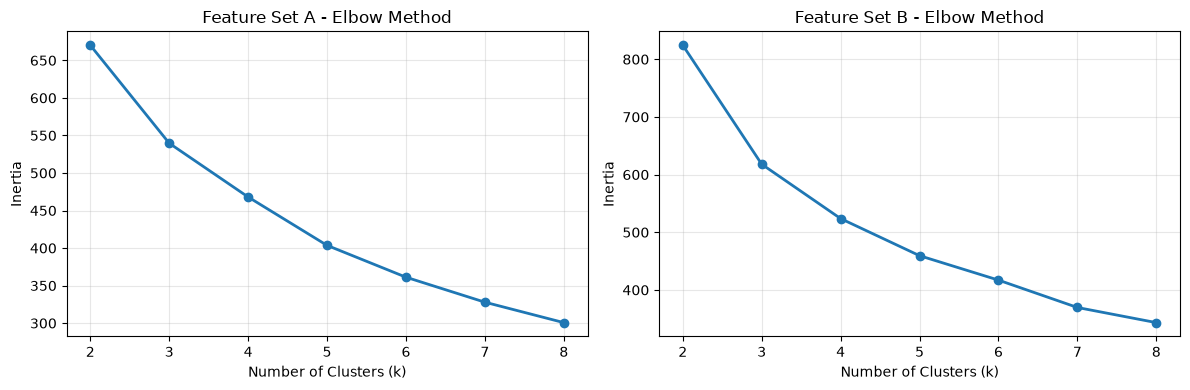

In [32]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, set_name in zip(axes, ["A", "B"]):

    data = kmeans_results[
        kmeans_results["Feature Set"] == set_name
    ]

    ax.plot(
        data["k"],
        data["Inertia"],
        marker="o",
        linewidth=2
    )

    ax.set_title(f"Feature Set {set_name} - Elbow Method")
    ax.set_xlabel("Number of Clusters (k)")
    ax.set_ylabel("Inertia")
    ax.set_xticks(range(2, 9))
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [33]:

# Feature Set A: 2 küme
kmeans_A = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

# Feature Set B: 3 küme
kmeans_B = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

# Kümeleri oluştur
clustered_A = ml_features.copy()
clustered_B = ml_features.copy()

clustered_A["cluster"] = kmeans_A.fit_predict(X_A_scaled)
clustered_B["cluster"] = kmeans_B.fit_predict(X_B_scaled)

# İnceleyeceğimiz özellikler
profile_features = [
    "ev_sales_share",
    "ev_stock_share",
    "ev_stock",
    "slow_per_1000_evs",
    "fast_per_1000_evs",
    "ultra_fast_per_1000_evs"
]

# Her kümenin özelliklerini özetle
for name, data in [
    ("Feature Set A - k=2", clustered_A),
    ("Feature Set B - k=3", clustered_B)
]:
    print(f"\n{name}")

    profile = data.groupby("cluster").agg(
        observations=("year", "size"),
        unique_countries=("region_country", "nunique"),
        **{
            feature: (feature, "median")
            for feature in profile_features
        }
    )

    display(profile.round(2))



Feature Set A - k=2


,observations,unique_countries,ev_sales_share,ev_stock_share,ev_stock,slow_per_1000_evs,fast_per_1000_evs,ultra_fast_per_1000_evs
cluster,,,,,,,,
0,141,27,22.0,3.0,300000.0,42.31,6.18,4.36
1,44,13,2.1,0.2,17500.0,119.17,40.27,5.27



Feature Set B - k=3


,observations,unique_countries,ev_sales_share,ev_stock_share,ev_stock,slow_per_1000_evs,fast_per_1000_evs,ultra_fast_per_1000_evs
cluster,,,,,,,,
0,114,26,16.5,2.4,250000.0,42.58,6.65,3.91
1,27,8,58.0,14.0,580000.0,42.27,3.64,7.34
2,44,13,2.1,0.2,17500.0,119.17,40.27,5.27


In [34]:

# 2025 yılındaki ülkelerin küme üyelikleri

for name, data in [
    ("Feature Set A - k=2", clustered_A),
    ("Feature Set B - k=3", clustered_B)
]:
    print(f"\n{name} | 2025")

    data_2025 = data[data["year"] == 2025]

    countries_by_cluster = (
        data_2025
        .groupby("cluster")["region_country"]
        .apply(lambda countries: ", ".join(sorted(countries)))
        .reset_index(name="Countries")
    )

    countries_by_cluster["Country Count"] = (
        data_2025.groupby("cluster")["region_country"]
        .nunique()
        .values
    )

    display(countries_by_cluster)



Feature Set A - k=2 | 2025


,cluster,Countries,Country Count
0,0,"Australia, Austria, Belgium, Canada, China, De...",26
1,1,"Chile, Greece, India, Jordan, Korea, Russia, S...",7



Feature Set B - k=3 | 2025


,cluster,Countries,Country Count
0,0,"Australia, Austria, Canada, France, Germany, I...",18
1,1,"Belgium, China, Denmark, Finland, Iceland, Net...",8
2,2,"Chile, Greece, India, Jordan, Korea, Russia, S...",7


In [35]:

# 2025 yılı için Feature Set A küme üyelikleri
countries_A = (
    clustered_A[clustered_A["year"] == 2025]
    [["region_country", "cluster"]]
    .rename(columns={"cluster": "Cluster A"})
)

# 2025 yılı için Feature Set B küme üyelikleri
countries_B = (
    clustered_B[clustered_B["year"] == 2025]
    [["region_country", "cluster"]]
    .rename(columns={"cluster": "Cluster B"})
)

# İki modelin sonuçlarını ülke bazında birleştir
comparison = countries_A.merge(
    countries_B,
    on="region_country",
    validate="one_to_one"
)

# Her ülkenin iki modeldeki kümesini göster
display(
    comparison.sort_values(
        ["Cluster B", "region_country"]
    ).reset_index(drop=True)
)

# İki model arasındaki küme dağılımını karşılaştır
print("Cluster Comparison:")
display(
    pd.crosstab(
        comparison["Cluster A"],
        comparison["Cluster B"]
    )
)


,region_country,Cluster A,Cluster B
0,Australia,0,0
1,Austria,0,0
2,Canada,0,0
3,France,0,0
4,Germany,0,0
5,Indonesia,0,0
6,Israel,0,0
7,Italy,0,0
8,Mexico,0,0
9,New Zealand,0,0


Cluster Comparison:


Cluster B,0,1,2
Cluster A,,,
0,18,8,0
1,0,0,7


In [36]:

# Sadece 2025 yılındaki gözlemleri seç
data_A_2025 = clustered_A[
    clustered_A["year"] == 2025
].copy()

data_B_2025 = clustered_B[
    clustered_B["year"] == 2025
].copy()

# İncelenecek sayısal özellikler
profile_features = [
    "ev_sales_share",
    "ev_stock_share",
    "ev_stock",
    "slow_per_1000_evs",
    "fast_per_1000_evs",
    "ultra_fast_per_1000_evs"
]

for name, data in [
    ("Feature Set A - 2025", data_A_2025),
    ("Feature Set B - 2025", data_B_2025)
]:
    print(f"\n{name}")

    profiles = data.groupby("cluster").agg(
        country_count=("region_country", "nunique"),
        **{
            feature: (feature, "median")
            for feature in profile_features
        }
    )

    display(profiles.round(2))



Feature Set A - 2025


,country_count,ev_sales_share,ev_stock_share,ev_stock,slow_per_1000_evs,fast_per_1000_evs,ultra_fast_per_1000_evs
cluster,,,,,,,
0,26,30.5,6.50,530000.0,36.55,6.53,6.58
1,7,4.0,0.75,59000.0,70.00,39.13,1.18



Feature Set B - 2025


,country_count,ev_sales_share,ev_stock_share,ev_stock,slow_per_1000_evs,fast_per_1000_evs,ultra_fast_per_1000_evs
cluster,,,,,,,
0,18,20.5,4.00,410000.0,30.42,7.59,4.90
1,8,59.5,15.00,790000.0,57.51,3.11,9.62
2,7,4.0,0.75,59000.0,70.00,39.13,1.18


In [37]:

from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

# Her iki özellik seti için aynı küme sayısı
model_A_k3 = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

model_B_k3 = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

# Küme etiketlerini hesapla
labels_A_k3 = model_A_k3.fit_predict(X_A_scaled)
labels_B_k3 = model_B_k3.fit_predict(X_B_scaled)

# Ülke-yıl bazında karşılaştırma tablosu
comparison_k3 = ml_features[
    ["region_country", "year"]
].copy()

comparison_k3["A_k3"] = labels_A_k3
comparison_k3["B_k3"] = labels_B_k3

# Tüm 185 gözlemde kümelerin uyuşma düzeyi
ari = adjusted_rand_score(
    labels_A_k3,
    labels_B_k3
)

print(f"Adjusted Rand Index: {ari:.3f}")

# Sadece 2025 yılı için karşılaştırma
comparison_2025 = comparison_k3[
    comparison_k3["year"] == 2025
]

print("\n2025 Cluster Comparison:")
display(
    pd.crosstab(
        comparison_2025["A_k3"],
        comparison_2025["B_k3"]
    )
)

# 2025 ülke listesi
display(
    comparison_2025.sort_values(
        ["B_k3", "region_country"]
    ).reset_index(drop=True)
)


Adjusted Rand Index: 0.444

2025 Cluster Comparison:


B_k3,0,1,2
A_k3,,,
0,10,8,0
1,8,0,1
2,0,0,6


,region_country,year,A_k3,B_k3
0,Australia,2025,1,0
1,Austria,2025,0,0
2,Canada,2025,1,0
3,France,2025,0,0
4,Germany,2025,0,0
5,Indonesia,2025,1,0
6,Israel,2025,1,0
7,Italy,2025,0,0
8,Mexico,2025,1,0
9,New Zealand,2025,1,0


In [38]:

# Feature Set A, k=3 için 2025 küme profilleri

a_k3_2025 = ml_features[
    ml_features["year"] == 2025
].copy()

# A modelinin k=3 küme etiketlerini ekle
a_k3_2025["cluster"] = comparison_k3.loc[
    a_k3_2025.index, "A_k3"
]

profile_features = [
    "ev_sales_share",
    "ev_stock_share",
    "ev_stock",
    "slow_per_1000_evs",
    "fast_per_1000_evs",
    "ultra_fast_per_1000_evs"
]

profile_A_k3 = a_k3_2025.groupby("cluster").agg(
    country_count=("region_country", "nunique"),
    **{
        feature: (feature, "median")
        for feature in profile_features
    }
)

display(profile_A_k3.round(2))

# İki modelin 2025 sonuçlarının benzerliği
ari_2025 = adjusted_rand_score(
    comparison_2025["A_k3"],
    comparison_2025["B_k3"]
)

print(f"2025 Adjusted Rand Index: {ari_2025:.3f}")


,country_count,ev_sales_share,ev_stock_share,ev_stock,slow_per_1000_evs,fast_per_1000_evs,ultra_fast_per_1000_evs
cluster,,,,,,,
0,18,36.5,7.5,730000.0,53.41,6.09,9.15
1,9,14.0,3.0,190000.0,18.42,7.00,3.02
2,6,4.0,0.6,71500.0,95.17,43.37,3.03


2025 Adjusted Rand Index: 0.304


# K-Means Clustering — Methodology, Results and Comparative Analysis

## 1. Problem Definition

Bu çalışmada ülkelerin elektrikli otomobil benimseme düzeyleri, EV pazar büyüklükleri ve halka açık şarj altyapısı özelliklerine göre benzer gruplara ayrılması amaçlanmaktadır.

**Research Question:**

*Which countries exhibit similar electric vehicle adoption and charging infrastructure characteristics?*

K-Means Clustering, gözetimsiz öğrenme (Unsupervised Learning) yöntemi olduğundan önceden tanımlanmış küme etiketlerine ihtiyaç duymaz. Algoritma, ülke-yıl gözlemlerinin sayısal özellikleri arasındaki benzerlikleri kullanarak kümeler oluşturur.

Bu çalışmada kümeleme birimi **country-year observation** olarak belirlenmiştir. Dolayısıyla aynı ülke farklı yıllarda farklı kümelerde bulunabilir.

## 2. Dataset Preparation

Kümeleme için IEA Global EV Outlook 2026 veri setinin 2020–2025 dönemine ait tarihsel kayıtları kullanılmıştır.

Veri seçiminde:

- `category = Historical`
- `year = 2020–2025`
- `Aggregate group = Other` veya `Projection_country`

koşulları uygulanmıştır.

`parameter`, `mode` ve `powertrain` kombinasyonları aracılığıyla EV satış payı, EV stok göstergeleri ve halka açık şarj noktası sayıları seçilmiştir.

### Dataset Summary

| Özellik | Değer |
|---|---:|
| Veri dönemi | 2020–2025 |
| Benzersiz ülke sayısı | 33 |
| Toplam ülke-yıl gözlemi | 185 |
| Başlangıç sayısal özellik sayısı | 6 |
| Seçilen ML tablosunda eksik değer | 0 |
| Modelleme yöntemi | Unsupervised Learning |

Altı temel göstergenin tamamına sahip olmayan ülke-yıl kayıtları analiz dışı bırakılmıştır.

### Feature Engineering

Mutlak şarj noktası sayılarının ülkenin EV pazar büyüklüğünden etkilenmesi nedeniyle şarj altyapısını normalize eden üç özellik oluşturulmuştur:

- `slow_per_1000_evs = public_slow / ev_stock × 1000`
- `fast_per_1000_evs = public_fast / ev_stock × 1000`
- `ultra_fast_per_1000_evs = public_ultra_fast / ev_stock × 1000`

Bu özellikler, her 1.000 elektrikli otomobile karşılık gelen halka açık şarj noktası sayısını ifade etmektedir.

Şarj yoğunluğu göstergelerinin paydasında otomobil EV stoku kullanılırken, şarj noktalarının farklı elektrikli araç türleri tarafından da kullanılabileceği dikkate alınmalıdır. Dolayısıyla bu göstergeler altyapı yeterliliğinin doğrudan ölçümü değildir.

## 3. Feature Sets and Preprocessing

Korelasyon analizinde `ev_sales_share` ve `ev_stock_share` arasında yüksek pozitif ilişki tespit edilmiştir (Pearson r ≈ 0.92).

Bu ilişkinin kümeleme sonuçları üzerindeki etkisini araştırmak amacıyla iki alternatif özellik seti oluşturulmuştur.

### Feature Set A — 5 Features

| Feature | Description |
|---|---|
| `ev_sales_share` | EV satış payı (%) |
| `ev_stock` | Elektrikli otomobil stoku |
| `slow_per_1000_evs` | 1.000 EV başına slow şarj noktası |
| `fast_per_1000_evs` | 1.000 EV başına fast şarj noktası |
| `ultra_fast_per_1000_evs` | 1.000 EV başına ultra-fast şarj noktası |

### Feature Set B — 6 Features

Feature Set A'daki beş özelliğe ek olarak `ev_stock_share` (elektrikli otomobillerin toplam otomobil stokundaki payı) kullanılmıştır.

### Preprocessing

Kümeleme öncesinde:

1. EV stokuna ve üç şarj yoğunluğu özelliğine `log1p()` dönüşümü uygulanmıştır.
2. Yüzde cinsinden EV satış ve stok payları logaritmik dönüşüme tabi tutulmamıştır.
3. Her iki özellik seti ayrı ayrı `StandardScaler` ile standartlaştırılmıştır.
4. Ülke adı ve yıl bilgileri kümeleme girdilerine dahil edilmemiş, sonuçların yorumlanması için korunmuştur.

Standardizasyon sonrasında sayısal özelliklerin ortalamaları yaklaşık 0, standart sapmaları 1 olmuştur.

Böylece farklı ölçekteki özelliklerin uzaklık hesaplamaları üzerindeki etkisi azaltılmıştır.

## 4. K-Means Model Training

K-Means algoritması, gözlemleri en yakın küme merkezine (centroid) atayarak küme içi kareli uzaklıkların toplamını minimize etmeye çalışır.

Uygulamada aşağıdaki parametreler kullanılmıştır:

| Parametre | Değer |
|---|---|
| Algorithm | K-Means |
| `k` aralığı | 2–8 |
| `random_state` | 42 |
| `n_init` | 10 |
| Feature Sets | A ve B |
| Toplam deney sayısı | 14 |

Modeller 185 ülke-yıl gözleminin tamamı kullanılarak eğitilmiştir.

Bu aşamada amaç gelecek yıllara yönelik tahmin yapmak değil, mevcut verideki benzerlik yapılarını keşfetmektir. Bu nedenle ayrı bir Train-Test bölmesi uygulanmamıştır.

## 5. K-Means Evaluation Results

Kümeleme sonuçları Silhouette Score, Inertia ve küme büyüklükleri kullanılarak değerlendirilmiştir.

### 5.1. Silhouette Score

Silhouette Score, bir gözlemin kendi kümesindeki gözlemlere yakınlığını ve diğer kümelerden ayrışmasını değerlendirir.

Skorun yüksek olması, ilgili özellik uzayında daha belirgin küme ayrımı bulunduğunu gösterir.

| k | Feature Set A | Feature Set B |
|---:|---:|---:|
| 2 | **0.313** | 0.222 |
| 3 | 0.224 | **0.290** |
| 4 | 0.222 | 0.223 |
| 5 | 0.238 | 0.235 |
| 6 | 0.226 | 0.225 |
| 7 | 0.255 | 0.244 |
| 8 | 0.246 | 0.247 |

**Findings:**

- Feature Set A için en yüksek Silhouette Score, `k=2` ile **0.313** olmuştur.
- Feature Set B için en yüksek Silhouette Score, `k=3` ile **0.290** olmuştur.
- Her iki özellik setinde de küme ayrışması sınırlı düzeydedir.
- Farklı boyuttaki özellik uzaylarında hesaplanan Silhouette skorları, modellerin birbirine mutlak üstünlüğünü tek başına belirlemek için yeterli değildir.

### 5.2. Elbow Method

Her özellik seti için farklı küme sayılarındaki Inertia değerleri incelenmiştir.

- Feature Set A'da Inertia, küme sayısı arttıkça düzenli olarak azalmıştır. Ancak belirgin ve tek bir dirsek noktası gözlenmemiştir.
- Feature Set B'de özellikle `k=2` ile `k=3` arasında büyük bir azalma görülmüş, sonraki değerlerde azalma kademeli olarak yavaşlamıştır.

Elbow grafikleri, tek başına kesin bir küme sayısı belirlemek yerine Silhouette analizini desteklemek amacıyla kullanılmıştır.

Bu değerlendirmeler sonucunda ayrıntılı analiz için iki temel aday belirlenmiştir:

- **Feature Set A: k=2**
- **Feature Set B: k=3**

## 6. Cluster Interpretation — Feature Set A (k=2)

Modeller 2020–2025 verileri üzerinde eğitilmiş, kümelerin yorumlanması için 2025 yılına ait 33 ülkenin özellikleri incelenmiştir.

### 2025 Cluster Profiles

| Feature (Median) | Cluster 0 | Cluster 1 |
|---|---:|---:|
| Country Count | 26 | 7 |
| EV Sales Share (%) | 30.5 | 4.0 |
| EV Stock Share (%) | 6.50 | 0.75 |
| EV Stock | 530,000 | 59,000 |
| Slow / 1,000 EVs | 36.55 | 70.00 |
| Fast / 1,000 EVs | 6.53 | 39.13 |
| Ultra-fast / 1,000 EVs | 6.58 | 1.18 |

### Cluster 0 — Higher EV Adoption and Larger Markets

Bu kümede EV satış ve stok payları, diğer kümeye göre daha yüksektir.

EV stoku medyanının 530.000 olması, grubun daha büyük elektrikli otomobil pazarlarını içerdiğini göstermektedir.

### Cluster 1 — Lower EV Adoption with Higher Slow/Fast Charger Density

Bu kümede EV satış payı medyanı yalnızca %4 ve EV stoku medyanı 59.000'dir.

Buna karşılık slow ve fast şarj yoğunluğu daha yüksektir.

Bu farklılık, EV stokunun küçük olması nedeniyle oranların yükselmesinden kısmen kaynaklanabilir.

**Interpretation:** Feature Set A, `k=2` ile ülkeleri temel olarak daha yüksek ve daha düşük EV benimseme profillerine ayırmaktadır. Ancak yüksek benimseme grubunun kendi içindeki farklılıklarını ayrıntılı biçimde göstermemektedir.

## 7. Cluster Interpretation — Feature Set B (k=3)

Feature Set B'ye `ev_stock_share` eklendiğinde, en yüksek Silhouette Score üç kümeli modelde elde edilmiştir.

### 2025 Cluster Profiles

| Feature (Median) | Cluster 0 | Cluster 1 | Cluster 2 |
|---|---:|---:|---:|
| Country Count | 18 | 8 | 7 |
| EV Sales Share (%) | 20.5 | 59.5 | 4.0 |
| EV Stock Share (%) | 4.00 | 15.00 | 0.75 |
| EV Stock | 410,000 | 790,000 | 59,000 |
| Slow / 1,000 EVs | 30.42 | 57.51 | 70.00 |
| Fast / 1,000 EVs | 7.59 | 3.11 | 39.13 |
| Ultra-fast / 1,000 EVs | 4.90 | 9.62 | 1.18 |

### Cluster 0 — Intermediate EV Adoption

**18 countries**

Australia, Austria, Canada, France, Germany, Indonesia, Israel, Italy, Mexico, New Zealand, Poland, Portugal, Singapore, Spain, Switzerland, Turkiye, USA, United Kingdom.

Bu grubun EV satış payı medyanı %20,5 ve EV stok payı medyanı %4'tür.

Küme, elektrikli otomobil pazarının belirli bir gelişim seviyesine ulaştığı ancak yüksek benimseme grubundan ayrılan ülkeleri içermektedir.

### Cluster 1 — Advanced EV Adoption

**8 countries**

Belgium, China, Denmark, Finland, Iceland, Netherlands, Norway, Sweden.

Bu küme, EV benimseme göstergelerinde en yüksek medyan değerlere sahiptir.

- EV Sales Share: %59,5
- EV Stock Share: %15
- EV Stock: 790.000
- Ultra-fast charger density: 9,62 / 1.000 EV

Bu nedenle küme, yüksek EV benimseme seviyesine sahip pazar profili olarak yorumlanmıştır.

### Cluster 2 — Early EV Adoption with High Relative Fast-Charging Density

**7 countries**

Chile, Greece, India, Jordan, Korea, Russia, South Africa.

Bu küme en düşük EV benimseme göstergelerine sahiptir.

- EV Sales Share: %4
- EV Stock Share: %0,75
- EV Stock: 59.000
- Fast charger density: 39,13 / 1.000 EV

Fast şarj yoğunluğunun yüksek olması, mutlak şarj altyapısının daha gelişmiş olduğu anlamına gelmez. EV stoku küçük olduğunda normalize edilmiş oranlar yüksek olabilir.

**Interpretation:** Feature Set B, ülkeleri EV benimseme düzeyleri bakımından üç farklı profilde gruplandırmaktadır. Şarj altyapısı yoğunlukları ise bu profiller arasında ek farklılıklar göstermektedir.

## 8. Controlled Comparison — Feature Set A vs. B (k=3)

Feature Set A (`k=2`) ile Feature Set B (`k=3`) karşılaştırmasında hem özellik seti hem küme sayısı değiştiği için farklılıkların nedeni doğrudan belirlenememektedir.

Bu sorunu azaltmak amacıyla her iki özellik seti de aynı küme sayısıyla (`k=3`) yeniden eğitilmiştir.

### 8.1. Feature Set A (k=3) — 2025 Profiles

| Feature (Median) | Cluster 0 | Cluster 1 | Cluster 2 |
|---|---:|---:|---:|
| Country Count | 18 | 9 | 6 |
| EV Sales Share (%) | 36.5 | 14.0 | 4.0 |
| EV Stock Share (%) | 7.5 | 3.0 | 0.6 |
| EV Stock | 730,000 | 190,000 | 71,500 |
| Slow / 1,000 EVs | 53.41 | 18.42 | 95.17 |
| Fast / 1,000 EVs | 6.09 | 7.00 | 43.37 |
| Ultra-fast / 1,000 EVs | 9.15 | 3.02 | 3.03 |

Bu modelde:

- Cluster 0: Daha yüksek EV benimsemesi ve ultra-fast şarj yoğunluğu
- Cluster 1: Daha düşük EV benimsemesi ve görece düşük slow şarj yoğunluğu
- Cluster 2: Düşük EV benimsemesi ve yüksek göreli slow/fast şarj yoğunluğu

profilleri gözlenmiştir.

Feature Set A'nın üç kümeli çözümü, benimseme düzeyinin yanında şarj yoğunluğu farklılıklarını da belirginleştirmektedir.

### 8.2. Cluster Membership Comparison

2025 yılında iki modelin aynı ülkelere atadığı küme etiketleri karşılaştırılmıştır.

| A (k=3) / B (k=3) | B Cluster 0 | B Cluster 1 | B Cluster 2 |
|---|---:|---:|---:|
| A Cluster 0 | 10 | 8 | 0 |
| A Cluster 1 | 8 | 0 | 1 |
| A Cluster 2 | 0 | 0 | 6 |

**Findings:**

- B modelinin yüksek benimseme kümesindeki 8 ülke, A modelinde daha geniş bir küme içerisinde yer almaktadır.
- B modelinin orta benimseme kümesindeki 18 ülke, A modelinde iki farklı kümeye dağılmıştır.
- Düşük benimseme grubundaki 6 ülke iki modelde de birlikte kalmıştır.
- Jordan, B'nin düşük benimseme grubunda bulunurken A'nın diğer kümesine yerleşmiştir.

Bu sonuçlar, `ev_stock_share` özelliğinin eklenmesinin kümelerin yapısını etkilediğini göstermektedir.

### 8.3. Adjusted Rand Index (ARI)

İki modelin 2025 yılı için oluşturduğu küme etiketleri Adjusted Rand Index ile karşılaştırılmıştır.

**2025 Adjusted Rand Index: 0.304**

ARI, iki kümelemenin gözlemleri benzer biçimde gruplandırıp gruplandırmadığını ölçer.

- ARI = 1: Tam uyum
- ARI ≈ 0: Rastlantısal beklenti düzeyinde uyum
- ARI negatif: Rastlantısal beklentiden düşük uyum

Elde edilen **0.304** değeri, iki model arasında sınırlı düzeyde kümeleme uyumu olduğunu göstermektedir.

Bu değer, modellerin %30,4 doğrulukla çalıştığı anlamına gelmez.

ARI, gerçek küme etiketleriyle ölçülen bir doğruluk metriği değil, iki kümeleme sonucunun benzerliğini değerlendiren bir ölçüttür.

## 9. Comparative Evaluation

| Evaluation Criterion | Feature Set A | Feature Set B |
|---|---|---|
| Number of Features | 5 | 6 |
| Best Silhouette k | 2 | 3 |
| Best Silhouette Score | 0.313 | 0.290 |
| k=3 Silhouette Score | 0.224 | 0.290 |
| 2025 Cluster Sizes (k=3) | 18 / 9 / 6 | 18 / 8 / 7 |
| Primary Interpretation | EV adoption, market size and charging density | EV adoption, stock share and charging density |
| Separates High-Adoption Countries into a Distinct Cluster? | Not clearly | Yes |
| Final Model Selected? | No | No |

### Main Findings

1. Her iki özellik seti de yorumlanabilir ülke-yıl kümeleri oluşturmuştur.
2. Feature Set A'nın en yüksek Silhouette Score değeri `k=2` için 0.313 olmuştur.
3. Feature Set B'nin en yüksek Silhouette Score değeri `k=3` için 0.290 olmuştur.
4. Feature Set B, 2025 yılında yüksek EV benimseme düzeyine sahip sekiz ülkeyi ayrı bir kümede toplamıştır.
5. Feature Set A, özellikle şarj yoğunluğu ve pazar ölçeği farklılıklarını öne çıkaran alternatif bir kümeleme sunmuştur.
6. Aynı `k=3` koşulunda 2025 yılı ARI değerinin 0.304 olması, sonuçların özellik seçimine duyarlı olduğunu göstermiştir.

### Limitations

- Kümeleme için gerçek sınıf etiketleri bulunmadığından kümelerin nesnel doğruluğu doğrudan hesaplanamamıştır.
- Silhouette skorları sınırlı ayrışmaya işaret etmektedir.
- 185 ülke-yıl gözlemi, 185 bağımsız ülkeyi temsil etmemektedir.
- EV stoku, ülkelerin pazar büyüklüğünden ve zaman içindeki büyümeden etkilenmektedir.
- Şarj yoğunluğu göstergeleri aynı EV stoku paydasını kullandığından matematiksel olarak birbirleriyle ilişkili olabilir.
- Farklı özellik setlerinin Silhouette skorları, özellik uzayları farklı olduğu için doğrudan kesin üstünlük ölçütü olarak değerlendirilmemelidir.
- Küme profilleri 2025 yılı özelinde yorumlanmıştır; modelin eğitimi ise 2020–2025 gözlemleri üzerinde gerçekleştirilmiştir.
- Elde edilen kümeler henüz farklı algoritmalar veya örnekleme temelli kararlılık analizleriyle doğrulanmamıştır.

## 10. K-Means Conclusion

K-Means algoritması, EV benimseme ve şarj altyapısı özellikleri açısından farklı ülke-yıl profilleri ortaya çıkarmıştır.

Feature Set A, yüksek ve düşük EV benimseme düzeylerini ayırmakta; üç kümeli çözümde ise şarj yoğunluğu farklılıklarını da belirginleştirmektedir.

Feature Set B, EV satış ve stok paylarını birlikte değerlendirerek düşük, orta ve yüksek benimseme profilleri oluşturmuştur.

Bununla birlikte **özellik seçiminin kümeleme sonuçlarını etkilediği ve Silhouette skorlarının güçlü bir ayrışma göstermediği** belirlenmiştir.

Bu nedenle henüz nihai özellik seti veya kümeleme algoritması seçilmemiştir.

Bir sonraki aşamada **Agglomerative Hierarchical Clustering** ve daha sonra **DBSCAN** uygulanarak farklı yöntemlerin benzer küme yapılarını ortaya çıkarıp çıkarmadığı değerlendirilecektir.

# 3. Sıradaki aşama — Agglomerative Hierarchical Clustering

In [39]:

from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
import pandas as pd

agg_results = []

feature_sets = {
    "A": X_A_scaled,
    "B": X_B_scaled
}

for set_name, X_data in feature_sets.items():

    for k in range(2, 9):

        model = AgglomerativeClustering(
            n_clusters=k,
            linkage="ward"
        )

        labels = model.fit_predict(X_data)

        cluster_sizes = pd.Series(labels).value_counts()

        agg_results.append({
            "Feature Set": set_name,
            "k": k,
            "Silhouette Score": silhouette_score(
                X_data, labels
            ),
            "Min Cluster Size": cluster_sizes.min(),
            "Max Cluster Size": cluster_sizes.max()
        })

agg_results_df = pd.DataFrame(agg_results)

display(agg_results_df.round(3))


,Feature Set,k,Silhouette Score,Min Cluster Size,Max Cluster Size
0,A,2,0.321,40,145
1,A,3,0.198,40,90
2,A,4,0.205,21,69
3,A,5,0.216,12,69
4,A,6,0.231,5,69
5,A,7,0.239,5,63
6,A,8,0.240,5,63
7,B,2,0.286,42,143
8,B,3,0.283,23,120
9,B,4,0.186,23,64


In [40]:

from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score
import pandas as pd

# Agglomerative - Feature Set A
agg_model_A = AgglomerativeClustering(
    n_clusters=2,
    linkage="ward"
)

# Agglomerative - Feature Set B
agg_model_B = AgglomerativeClustering(
    n_clusters=3,
    linkage="ward"
)

clustered_agg_A = ml_features.copy()
clustered_agg_B = ml_features.copy()

clustered_agg_A["cluster"] = (
    agg_model_A.fit_predict(X_A_scaled)
)

clustered_agg_B["cluster"] = (
    agg_model_B.fit_predict(X_B_scaled)
)

# K-Means ve Agglomerative karşılaştırması
comparison_results = []

for name, kmeans_data, agg_data in [
    ("A - k=2", clustered_A, clustered_agg_A),
    ("B - k=3", clustered_B, clustered_agg_B)
]:

    # Tüm 185 gözlem
    ari_all = adjusted_rand_score(
        kmeans_data["cluster"],
        agg_data["cluster"]
    )

    # Sadece 2025 gözlemleri
    mask_2025 = agg_data["year"] == 2025

    ari_2025 = adjusted_rand_score(
        kmeans_data.loc[mask_2025, "cluster"],
        agg_data.loc[mask_2025, "cluster"]
    )

    comparison_results.append({
        "Feature Set": name,
        "ARI (2020-2025)": ari_all,
        "ARI (2025)": ari_2025
    })

    print(f"\n{name} - 2025 Cluster Comparison")

    display(
        pd.crosstab(
            kmeans_data.loc[mask_2025, "cluster"],
            agg_data.loc[mask_2025, "cluster"],
            rownames=["K-Means"],
            colnames=["Agglomerative"]
        )
    )

display(
    pd.DataFrame(comparison_results).round(3)
)



A - k=2 - 2025 Cluster Comparison


Agglomerative,0,1
K-Means,,
0,26,0
1,1,6



B - k=3 - 2025 Cluster Comparison


Agglomerative,0,1,2
K-Means,,,
0,17,0,1
1,3,0,5
2,1,6,0


,Feature Set,ARI (2020-2025),ARI (2025)
0,A - k=2,0.907,0.862
1,B - k=3,0.808,0.559


In [41]:

# Agglomerative Clustering - 2025 Cluster Profiles

profile_features = [
    "ev_sales_share",
    "ev_stock_share",
    "ev_stock",
    "slow_per_1000_evs",
    "fast_per_1000_evs",
    "ultra_fast_per_1000_evs"
]

for name, data in [
    ("Feature Set A - k=2", clustered_agg_A),
    ("Feature Set B - k=3", clustered_agg_B)
]:

    print(f"\n{name} | 2025 Cluster Profiles")

    data_2025 = data[data["year"] == 2025].copy()

    profiles = data_2025.groupby("cluster").agg(
        country_count=("region_country", "nunique"),
        **{
            feature: (feature, "median")
            for feature in profile_features
        }
    )

    display(profiles.round(2))

    print("\nCountries by Cluster:")

    for cluster, group in data_2025.groupby("cluster"):
        countries = sorted(group["region_country"].tolist())

        print(f"\nCluster {cluster} ({len(countries)} countries):")
        print(", ".join(countries))



Feature Set A - k=2 | 2025 Cluster Profiles


,country_count,ev_sales_share,ev_stock_share,ev_stock,slow_per_1000_evs,fast_per_1000_evs,ultra_fast_per_1000_evs
cluster,,,,,,,
0,27,30.0,6.0,430000.0,37.50,6.88,6.54
1,6,4.0,0.6,71500.0,95.17,43.37,3.03



Countries by Cluster:

Cluster 0 (27 countries):
Australia, Austria, Belgium, Canada, China, Denmark, Finland, France, Germany, Iceland, Indonesia, Israel, Italy, Jordan, Mexico, Netherlands, New Zealand, Norway, Poland, Portugal, Singapore, Spain, Sweden, Switzerland, Turkiye, USA, United Kingdom

Cluster 1 (6 countries):
Chile, Greece, India, Korea, Russia, South Africa

Feature Set B - k=3 | 2025 Cluster Profiles


,country_count,ev_sales_share,ev_stock_share,ev_stock,slow_per_1000_evs,fast_per_1000_evs,ultra_fast_per_1000_evs
cluster,,,,,,,
0,21,21.0,4.0,430000.0,35.60,7.00,5.00
1,6,4.0,0.6,71500.0,95.17,43.37,3.03
2,6,61.5,19.5,510000.0,40.18,4.66,9.62



Countries by Cluster:

Cluster 0 (21 countries):
Australia, Austria, Belgium, Canada, China, France, Germany, Indonesia, Israel, Italy, Jordan, Mexico, Netherlands, New Zealand, Poland, Portugal, Spain, Switzerland, Turkiye, USA, United Kingdom

Cluster 1 (6 countries):
Chile, Greece, India, Korea, Russia, South Africa

Cluster 2 (6 countries):
Denmark, Finland, Iceland, Norway, Singapore, Sweden


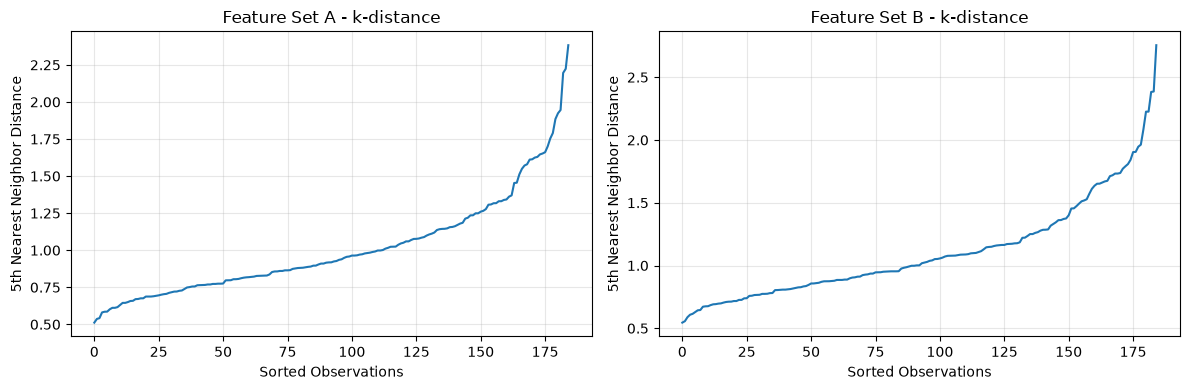

In [42]:

from sklearn.neighbors import NearestNeighbors
import numpy as np
import matplotlib.pyplot as plt

min_samples = 5

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, (set_name, X_data) in zip(
    axes,
    {
        "A": X_A_scaled,
        "B": X_B_scaled
    }.items()
):

    neighbors = NearestNeighbors(
        n_neighbors=min_samples
    )

    neighbors.fit(X_data)

    distances, indices = neighbors.kneighbors(X_data)

    # Her gözlemin 5. en yakın komşusuna uzaklığı
    k_distances = np.sort(distances[:, -1])

    ax.plot(k_distances)

    ax.set_title(f"Feature Set {set_name} - k-distance")
    ax.set_xlabel("Sorted Observations")
    ax.set_ylabel("5th Nearest Neighbor Distance")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [43]:

from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
import numpy as np
import pandas as pd

eps_values = {
    "A": [1.2, 1.4, 1.6, 1.8, 2.0],
    "B": [1.4, 1.6, 1.8, 2.0, 2.2]
}

feature_sets = {
    "A": X_A_scaled,
    "B": X_B_scaled
}

dbscan_results = []

for set_name, X_data in feature_sets.items():

    for eps in eps_values[set_name]:

        model = DBSCAN(
            eps=eps,
            min_samples=5
        )

        labels = model.fit_predict(X_data)

        # -1 etiketli gözlemler noise olarak kabul edilir
        noise_mask = labels == -1
        clustered_mask = ~noise_mask

        n_noise = noise_mask.sum()
        n_clusters = len(set(labels) - {-1})

        cluster_sizes = pd.Series(
            labels[clustered_mask]
        ).value_counts()

        # Silhouette yalnızca kümelenmiş gözlemlerde
        # ve en az iki küme varsa hesaplanır
        silhouette = np.nan

        if (
            n_clusters >= 2
            and clustered_mask.sum() > n_clusters
        ):
            silhouette = silhouette_score(
                X_data.loc[clustered_mask],
                labels[clustered_mask]
            )

        dbscan_results.append({
            "Feature Set": set_name,
            "eps": eps,
            "min_samples": 5,
            "Clusters": n_clusters,
            "Noise Count": n_noise,
            "Noise (%)": n_noise / len(labels) * 100,
            "Silhouette Score": silhouette,
            "Min Cluster Size": (
                cluster_sizes.min()
                if n_clusters > 0 else np.nan
            ),
            "Max Cluster Size": (
                cluster_sizes.max()
                if n_clusters > 0 else np.nan
            )
        })

dbscan_results_df = pd.DataFrame(dbscan_results)

display(dbscan_results_df.round(3))


,Feature Set,eps,min_samples,Clusters,Noise Count,Noise (%),Silhouette Score,Min Cluster Size,Max Cluster Size
0,A,1.2,5,6,17,9.189,0.270,5,137
1,A,1.4,5,3,7,3.784,0.237,5,167
2,A,1.6,5,2,3,1.622,0.359,5,177
3,A,1.8,5,2,1,0.541,0.348,5,179
4,A,2.0,5,2,1,0.541,0.348,5,179
5,B,1.4,5,2,23,12.432,0.369,5,157
6,B,1.6,5,3,8,4.324,0.338,5,167
7,B,1.8,5,2,1,0.541,0.308,5,179
8,B,2.0,5,2,1,0.541,0.308,5,179
9,B,2.2,5,1,0,0.000,NaN,185,185


In [44]:

from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
import numpy as np
import pandas as pd

parameter_grid = {
    "A": {
        "eps": [1.0, 1.2, 1.4],
        "min_samples": [4, 6, 8]
    },
    "B": {
        "eps": [1.2, 1.4, 1.6],
        "min_samples": [4, 6, 8]
    }
}

feature_sets = {
    "A": X_A_scaled,
    "B": X_B_scaled
}

tuning_results = []

for set_name, X_data in feature_sets.items():

    params = parameter_grid[set_name]

    for eps in params["eps"]:
        for min_samples in params["min_samples"]:

            model = DBSCAN(
                eps=eps,
                min_samples=min_samples
            )

            labels = model.fit_predict(X_data)

            noise_mask = labels == -1
            valid_mask = ~noise_mask

            n_clusters = len(set(labels) - {-1})
            noise_count = noise_mask.sum()

            cluster_sizes = (
                pd.Series(labels[valid_mask])
                .value_counts()
            )

            silhouette = np.nan

            if (
                n_clusters >= 2
                and valid_mask.sum() > n_clusters
            ):
                silhouette = silhouette_score(
                    X_data.loc[valid_mask],
                    labels[valid_mask]
                )

            largest_ratio = (
                cluster_sizes.max() / len(X_data) * 100
                if n_clusters > 0
                else np.nan
            )

            tuning_results.append({
                "Feature Set": set_name,
                "eps": eps,
                "min_samples": min_samples,
                "Clusters": n_clusters,
                "Noise (%)": noise_count / len(X_data) * 100,
                "Silhouette": silhouette,
                "Largest Cluster (%)": largest_ratio,
                "Cluster Sizes": sorted(
                    cluster_sizes.tolist(),
                    reverse=True
                )
            })

dbscan_tuning_df = pd.DataFrame(tuning_results)

display(dbscan_tuning_df.round(3))


,Feature Set,eps,min_samples,Clusters,Noise (%),Silhouette,Largest Cluster (%),Cluster Sizes
0,A,1.0,4,5,15.135,0.291,71.351,"[132, 9, 6, 5, 5]"
1,A,1.0,6,5,27.568,0.201,59.459,"[110, 9, 6, 6, 3]"
2,A,1.0,8,1,41.081,NaN,58.919,[109]
3,A,1.2,4,5,7.568,0.226,80.000,"[148, 6, 6, 6, 5]"
4,A,1.2,6,4,14.595,0.278,74.054,"[137, 9, 6, 6]"
5,A,1.2,8,2,22.162,0.418,73.514,"[136, 8]"
6,A,1.4,4,3,2.162,0.235,91.892,"[170, 6, 5]"
7,A,1.4,6,1,10.811,NaN,89.189,[165]
8,A,1.4,8,1,18.919,NaN,81.081,[150]
9,B,1.2,4,4,13.514,0.275,78.378,"[145, 6, 5, 4]"


In [45]:

from sklearn.cluster import DBSCAN
import pandas as pd

dbscan_candidates = {
    "A": {
        "data": X_A_scaled,
        "eps": 1.0,
        "min_samples": 4
    },
    "B": {
        "data": X_B_scaled,
        "eps": 1.2,
        "min_samples": 4
    }
}

for set_name, params in dbscan_candidates.items():

    model = DBSCAN(
        eps=params["eps"],
        min_samples=params["min_samples"]
    )

    labels = model.fit_predict(params["data"])

    result = ml_features[
        ["region_country", "year"]
    ].copy()

    result["cluster"] = labels

    print(f"\nFeature Set {set_name}")

    # Tüm yıllar için küme büyüklükleri
    print("\nCluster Sizes (2020-2025):")
    display(
        result["cluster"]
        .value_counts()
        .sort_index()
        .rename_axis("cluster")
        .reset_index(name="observations")
    )

    # Her yılın hangi kümelerde bulunduğu
    print("\nCluster Distribution by Year:")
    display(
        pd.crosstab(
            result["year"],
            result["cluster"]
        )
    )

    # 2025 yılındaki ülkeler
    print("\n2025 Countries by Cluster:")

    data_2025 = result[result["year"] == 2025]

    for cluster, group in data_2025.groupby("cluster"):

        countries = sorted(
            group["region_country"].tolist()
        )

        print(f"\nCluster {cluster}:")
        print(", ".join(countries))



Feature Set A

Cluster Sizes (2020-2025):


,cluster,observations
0,-1,28
1,0,132
2,1,9
3,2,5
4,3,5
5,4,6



Cluster Distribution by Year:


cluster,-1,0,1,2,3,4
year,,,,,,
2020,5,16,1,0,1,1
2021,8,17,3,1,1,1
2022,5,22,2,1,1,1
2023,5,23,2,1,0,1
2024,3,26,1,1,1,1
2025,2,28,0,1,1,1



2025 Countries by Cluster:

Cluster -1:
China, Singapore

Cluster 0:
Australia, Austria, Belgium, Canada, Chile, Denmark, Finland, France, Germany, Greece, Iceland, India, Indonesia, Israel, Italy, Jordan, Mexico, Netherlands, Poland, Portugal, Russia, South Africa, Spain, Sweden, Switzerland, Turkiye, USA, United Kingdom

Cluster 2:
Korea

Cluster 3:
New Zealand

Cluster 4:
Norway

Feature Set B

Cluster Sizes (2020-2025):


,cluster,observations
0,-1,25
1,0,145
2,1,5
3,2,6
4,3,4



Cluster Distribution by Year:


cluster,-1,0,1,2,3
year,,,,,
2020,6,17,0,1,0
2021,6,23,1,1,0
2022,3,26,1,1,1
2023,3,26,1,1,1
2024,3,27,1,1,1
2025,4,26,1,1,1



2025 Countries by Cluster:

Cluster -1:
China, Denmark, Iceland, Singapore

Cluster 0:
Australia, Austria, Belgium, Canada, Chile, Finland, France, Germany, Greece, India, Indonesia, Israel, Italy, Jordan, Mexico, Netherlands, Poland, Portugal, Russia, South Africa, Spain, Sweden, Switzerland, Turkiye, USA, United Kingdom

Cluster 1:
Korea

Cluster 2:
New Zealand

Cluster 3:
Norway


## Adım 8.1 — Model Evaluation

In [46]:

from sklearn.cluster import DBSCAN
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)
import numpy as np
import pandas as pd

# DBSCAN adaylarını yeniden oluştur
dbscan_A = DBSCAN(
    eps=1.0,
    min_samples=4
).fit_predict(X_A_scaled)

dbscan_B = DBSCAN(
    eps=1.2,
    min_samples=4
).fit_predict(X_B_scaled)

# Önceki algoritmaların küme etiketleri
models = [
    ("A", "K-Means", X_A_scaled,
     clustered_A["cluster"].to_numpy()),

    ("A", "Agglomerative", X_A_scaled,
     clustered_agg_A["cluster"].to_numpy()),

    ("A", "DBSCAN", X_A_scaled, dbscan_A),

    ("B", "K-Means", X_B_scaled,
     clustered_B["cluster"].to_numpy()),

    ("B", "Agglomerative", X_B_scaled,
     clustered_agg_B["cluster"].to_numpy()),

    ("B", "DBSCAN", X_B_scaled, dbscan_B)
]

evaluation_results = []

for feature_set, algorithm, X_data, labels in models:

    # DBSCAN noise gözlemlerini hariç tut
    valid_mask = labels != -1

    X_valid = X_data.loc[valid_mask]
    labels_valid = labels[valid_mask]

    n_clusters = len(np.unique(labels_valid))

    cluster_sizes = pd.Series(
        labels_valid
    ).value_counts()

    silhouette = np.nan
    dbi = np.nan
    chi = np.nan

    if 2 <= n_clusters < len(labels_valid):

        silhouette = silhouette_score(
            X_valid, labels_valid
        )

        dbi = davies_bouldin_score(
            X_valid, labels_valid
        )

        chi = calinski_harabasz_score(
            X_valid, labels_valid
        )

    evaluation_results.append({
        "Feature Set": feature_set,
        "Algorithm": algorithm,
        "Clusters": n_clusters,
        "Silhouette": silhouette,
        "Davies-Bouldin": dbi,
        "Calinski-Harabasz": chi,
        "Noise (%)": (
            (~valid_mask).mean() * 100
        ),
        "Largest Cluster (%)": (
            cluster_sizes.max()
            / len(X_data) * 100
        )
    })

evaluation_df = pd.DataFrame(
    evaluation_results
)

display(evaluation_df.round(3))


,Feature Set,Algorithm,Clusters,Silhouette,Davies-Bouldin,Calinski-Harabasz,Noise (%),Largest Cluster (%)
0,A,K-Means,2,0.313,1.318,69.574,0.000,76.216
1,A,Agglomerative,2,0.321,1.296,67.631,0.000,78.378
2,A,DBSCAN,5,0.291,0.636,30.514,15.135,71.351
3,B,K-Means,3,0.290,1.261,72.448,0.000,61.622
4,B,Agglomerative,3,0.283,1.267,64.829,0.000,64.865
5,B,DBSCAN,4,0.275,0.653,25.607,13.514,78.378


In [47]:

# Türkiye 2025 gözlemini seç
mask = (
    (ml_features["region_country"] == "Turkiye") &
    (ml_features["year"] == 2025)
)

# K-Means modeline verilen standartlaştırılmış özellikler
turkiye_features = X_B_scaled.loc[mask]

# Her küme merkezine uzaklık
distances = kmeans_B.transform(turkiye_features)[0]

distance_table = pd.DataFrame({
    "Cluster": range(len(distances)),
    "Distance to Centroid": distances
})

display(
    distance_table.sort_values("Distance to Centroid")
)

# Modelin atadığı küme
assigned_cluster = kmeans_B.predict(turkiye_features)[0]

print("Assigned Cluster:", assigned_cluster)


,Cluster,Distance to Centroid
0,0,2.034070
2,2,2.660850
1,1,3.397492


Assigned Cluster: 0


In [48]:

import pandas as pd

# Türkiye'nin 2025 yılı standartlaştırılmış özellikleri
turkiye = X_B_scaled.loc[
    (ml_features["region_country"] == "Turkiye") &
    (ml_features["year"] == 2025)
].iloc[0]

# Türkiye'nin atandığı küme
cluster_id = 0

# Cluster 0'ın merkezi
centroid = pd.Series(
    kmeans_B.cluster_centers_[cluster_id],
    index=X_B_scaled.columns
)

# Her özelliğin kareli uzaklığa katkısı
contributions = (turkiye - centroid) ** 2

contribution_table = pd.DataFrame({
    "Turkey (Scaled)": turkiye,
    "Cluster 0 Centroid": centroid,
    "Squared Difference": contributions,
    "Contribution (%)": (
        contributions / contributions.sum() * 100
    )
})

display(
    contribution_table.sort_values(
        "Contribution (%)",
        ascending=False
    ).round(3)
)

print(
    "Euclidean Distance:",
    round(contributions.sum() ** 0.5, 3)
)


,Turkey (Scaled),Cluster 0 Centroid,Squared Difference,Contribution (%)
ultra_fast_per_1000_evs,1.595,-0.128,2.971,71.800
fast_per_1000_evs,0.663,-0.360,1.047,25.315
slow_per_1000_evs,-0.091,-0.309,0.048,1.150
ev_stock,0.465,0.264,0.040,0.975
ev_sales_share,0.024,-0.153,0.031,0.758
ev_stock_share,-0.222,-0.227,0.000,0.001


Euclidean Distance: 2.034


In [49]:

# Türkiye'nin 2025 yılındaki özellikleri
turkiye = X_B_scaled.loc[
    (ml_features["region_country"] == "Turkiye") &
    (ml_features["year"] == 2025)
].iloc[0]

# En yakın iki küme merkezini belirle
distances = kmeans_B.transform(
    turkiye.to_frame().T
)[0]

nearest_two = np.argsort(distances)[:2]

first_cluster = nearest_two[0]
second_cluster = nearest_two[1]

# Küme merkezleri
centers = pd.DataFrame(
    kmeans_B.cluster_centers_,
    columns=X_B_scaled.columns
)

# Her özellik için kareli uzaklıklar
diff_first = (
    turkiye - centers.loc[first_cluster]
) ** 2

diff_second = (
    turkiye - centers.loc[second_cluster]
) ** 2

comparison = pd.DataFrame({
    f"Distance² to Cluster {first_cluster}": diff_first,
    f"Distance² to Cluster {second_cluster}": diff_second,
    "Advantage for Assigned Cluster": (
        diff_second - diff_first
    )
})

display(
    comparison.sort_values(
        "Advantage for Assigned Cluster",
        ascending=False
    ).round(3)
)

print(
    "Total Advantage:",
    round(comparison["Advantage for Assigned Cluster"].sum(), 3)
)


,Distance² to Cluster 0,Distance² to Cluster 2,Advantage for Assigned Cluster
ev_stock,0.040,2.200,2.160
slow_per_1000_evs,0.048,1.088,1.040
ev_sales_share,0.031,0.688,0.656
ev_stock_share,0.000,0.156,0.156
ultra_fast_per_1000_evs,2.971,2.477,-0.494
fast_per_1000_evs,1.047,0.471,-0.576


Total Advantage: 2.943


In [50]:

# Türkiye'nin 2020-2025 küme geçmişi
turkiye_history = clustered_B[
    clustered_B["region_country"] == "Turkiye"
][[
    "year",
    "cluster",
    "ev_sales_share",
    "ev_stock_share",
    "ev_stock",
    "slow_per_1000_evs",
    "fast_per_1000_evs",
    "ultra_fast_per_1000_evs"
]].sort_values("year")

display(turkiye_history.round(2))


,year,cluster,ev_sales_share,ev_stock_share,ev_stock,slow_per_1000_evs,fast_per_1000_evs,ultra_fast_per_1000_evs
168,2020,2,0.21,0.04,3900.0,333.33,15.38,0.26
169,2022,2,1.30,0.14,17000.0,129.41,10.59,10.59
170,2023,2,7.20,0.65,82000.0,85.37,29.27,8.05
171,2024,0,11.00,1.40,190000.0,31.58,16.32,14.74
172,2025,0,22.00,3.00,420000.0,50.00,20.95,15.00


In [51]:

# Feature Set B - K-Means (k=3)
# Ülkelerin yıllara göre küme üyelikleri

cluster_history = clustered_B.pivot(
    index="region_country",
    columns="year",
    values="cluster"
)

# Yılları sıralı göster
cluster_history = cluster_history.reindex(
    columns=range(2020, 2026)
)

display(cluster_history)

# Her yılda her kümede kaç ülke olduğunu göster
print("Cluster Distribution by Year:")

year_distribution = pd.crosstab(
    clustered_B["year"],
    clustered_B["cluster"]
)

display(year_distribution)


year,2020,2021,2022,2023,2024,2025
region_country,,,,,,
Australia,NaN,0.0,0.0,0.0,0.0,0.0
Austria,2.0,0.0,0.0,0.0,0.0,0.0
Belgium,0.0,0.0,0.0,0.0,1.0,1.0
Canada,0.0,0.0,0.0,0.0,0.0,0.0
Chile,2.0,2.0,2.0,2.0,2.0,2.0
China,0.0,0.0,0.0,0.0,1.0,1.0
Denmark,0.0,0.0,0.0,1.0,1.0,1.0
Finland,0.0,0.0,0.0,1.0,1.0,1.0
France,0.0,0.0,0.0,0.0,0.0,0.0


Cluster Distribution by Year:


cluster,0,1,2
year,,,
2020,16,1,7
2021,21,2,8
2022,21,3,8
2023,20,5,7
2024,18,8,7
2025,18,8,7


In [52]:

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import adjusted_rand_score
import numpy as np
import pandas as pd

# Önceden log dönüşümü uygulanmış Feature Set B
X = candidate_data[features_B].copy()

# Orijinal K-Means modelimizin küme etiketleri
baseline_labels = clustered_B["cluster"].to_numpy()

# Benzersiz ülkeler
countries = ml_features["region_country"].unique()

stability_results = []

# 30 farklı ülke alt örneklemiyle deneme
for seed in range(30):

    rng = np.random.default_rng(seed)

    selected_countries = rng.choice(
        countries,
        size=int(len(countries) * 0.8),
        replace=False
    )

    train_mask = (
        ml_features["region_country"]
        .isin(selected_countries)
        .to_numpy()
    )

    # Scaler yalnızca seçilen ülkelerle eğitilir
    scaler = StandardScaler()

    X_train = scaler.fit_transform(
        X.iloc[train_mask]
    )

    X_all = scaler.transform(X)

    # K-Means yeniden eğitilir
    model = KMeans(
        n_clusters=3,
        random_state=42,
        n_init=20
    )

    model.fit(X_train)

    # Karşılaştırma için tüm gözlemleri kümelendir
    new_labels = model.predict(X_all)

    ari = adjusted_rand_score(
        baseline_labels,
        new_labels
    )

    stability_results.append({
        "Run": seed + 1,
        "ARI": ari
    })

stability_df = pd.DataFrame(stability_results)

print("Cluster Stability Results:")
print("Mean ARI:", round(stability_df["ARI"].mean(), 3))
print("Median ARI:", round(stability_df["ARI"].median(), 3))
print("Min ARI:", round(stability_df["ARI"].min(), 3))
print("Max ARI:", round(stability_df["ARI"].max(), 3))

display(stability_df.round(3))



Cluster Stability Results:
Mean ARI: 0.93
Median ARI: 0.941
Min ARI: 0.795
Max ARI: 1.0


,Run,ARI
0,1,1.000
1,2,0.963
2,3,0.931
3,4,0.897
4,5,0.963
5,6,0.823
6,7,0.875
7,8,1.000
8,9,0.963
9,10,0.920


In [53]:

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import adjusted_rand_score
import numpy as np
import pandas as pd

configs = [
    ("A", features_A, 2, clustered_A["cluster"].to_numpy()),
    ("B", features_B, 3, clustered_B["cluster"].to_numpy())
]

countries = ml_features["region_country"].unique()
holdout_results = []

for seed in range(30):

    rng = np.random.default_rng(seed)

    train_countries = rng.choice(
        countries,
        size=int(len(countries) * 0.8),
        replace=False
    )

    train_mask = ml_features["region_country"].isin(
        train_countries
    ).to_numpy()

    test_mask = ~train_mask

    for set_name, features, k, baseline_labels in configs:

        # Log dönüşümü uygulanmış özellikler
        X = candidate_data[features].copy()

        # StandardScaler yalnızca eğitim ülkelerinde fit edilir
        scaler = StandardScaler()

        X_train = scaler.fit_transform(
            X.iloc[train_mask]
        )

        X_test = scaler.transform(
            X.iloc[test_mask]
        )

        model = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=10
        )

        model.fit(X_train)

        # Yalnızca eğitimde bulunmayan ülkeleri kümelendir
        predicted_labels = model.predict(X_test)

        ari = adjusted_rand_score(
            baseline_labels[test_mask],
            predicted_labels
        )

        holdout_results.append({
            "Feature Set": set_name,
            "Run": seed + 1,
            "ARI": ari
        })

holdout_df = pd.DataFrame(holdout_results)

summary = holdout_df.groupby("Feature Set")["ARI"].agg(
    ["mean", "median", "min", "max"]
)

display(summary.round(3))


,mean,median,min,max
Feature Set,,,,
A,0.911,1.0,0.182,1.0
B,0.956,1.0,0.577,1.0


In [54]:

# Seçilen model:
# K-Means | Feature Set B | k=3

final_clustering = clustered_B.copy()

# Kümelere yorumlanabilir isimler ekle
cluster_names = {
    0: "Intermediate EV Adoption",
    1: "Advanced EV Adoption",
    2: "Early EV Adoption"
}

final_clustering["cluster_name"] = (
    final_clustering["cluster"].map(cluster_names)
)

# Sonuçları CSV olarak kaydet
final_clustering.to_csv(
    output_dir / "clustering_results.csv",
    index=False
)

print("Saved: clustering_results.csv")
print("Shape:", final_clustering.shape)

display(
    final_clustering[
        ["region_country", "year", "cluster", "cluster_name"]
    ].head(10)
)


Saved: clustering_results.csv
Shape: (185, 13)


,region_country,year,cluster,cluster_name
0,Australia,2021,0,Intermediate EV Adoption
1,Australia,2022,0,Intermediate EV Adoption
2,Australia,2023,0,Intermediate EV Adoption
3,Australia,2024,0,Intermediate EV Adoption
4,Australia,2025,0,Intermediate EV Adoption
5,Austria,2020,2,Early EV Adoption
6,Austria,2021,0,Intermediate EV Adoption
7,Austria,2022,0,Intermediate EV Adoption
8,Austria,2023,0,Intermediate EV Adoption
9,Austria,2024,0,Intermediate EV Adoption


## Clustering Results Visualization

### Amaç

Bu bölümde, K-Means kümeleme algoritmasıyla elde edilen EV benimseme gruplarını görselleştirerek ülkeler arasındaki benzerlikleri ve farklılıkları inceleyeceğiz.

Görselleştirmelerin temel amaçları:

- Early, Intermediate ve Advanced kümelerindeki ülkelerin dağılımını karşılaştırmak.
- Kümelerin EV satış payı ve diğer pazar göstergeleri açısından nasıl farklılaştığını belirlemek.
- Ülkelerin 2020–2025 dönemindeki EV benimseme gelişimlerini incelemek.
- Dashboard'da kullanılabilecek anlamlı ve etkileşimli grafiklere karar vermek.

Grafikler önce notebook ortamında değerlendirilecek, ardından seçilen görselleştirmeler Streamlit dashboard'una entegre edilecektir.

In [2]:
import pandas as pd

# Kaydedilen Clustering sonuçlarını yükle
clustering_results = pd.read_csv("clustering_results.csv")

# Sütunları ve ilk 5 satırı incele
print("Veri seti boyutu:", clustering_results.shape)
print("\nSütunlar:")
print(clustering_results.columns.tolist())

display(clustering_results.head())

Veri seti boyutu: (185, 13)

Sütunlar:
['region_country', 'year', 'ev_sales_share', 'ev_stock', 'ev_stock_share', 'public_fast', 'public_slow', 'public_ultra_fast', 'slow_per_1000_evs', 'fast_per_1000_evs', 'ultra_fast_per_1000_evs', 'cluster', 'cluster_name']


,region_country,year,ev_sales_share,ev_stock,ev_stock_share,public_fast,public_slow,public_ultra_fast,slow_per_1000_evs,fast_per_1000_evs,ultra_fast_per_1000_evs,cluster,cluster_name
0,Australia,2021,2.7,48000.0,0.32,530.0,2000.0,250.0,41.666667,11.041667,5.208333,0,Intermediate EV Adoption
1,Australia,2022,5.1,88000.0,0.59,780.0,2100.0,390.0,23.863636,8.863636,4.431818,0,Intermediate EV Adoption
2,Australia,2023,11.0,190000.0,1.20,2100.0,5800.0,530.0,30.526316,11.052632,2.789474,0,Intermediate EV Adoption
3,Australia,2024,12.0,300000.0,1.90,3100.0,5100.0,710.0,17.000000,10.333333,2.366667,0,Intermediate EV Adoption
4,Australia,2025,15.0,430000.0,3.00,3900.0,5900.0,1300.0,13.720930,9.069767,3.023256,0,Intermediate EV Adoption


In [5]:
%pip install "nbformat>=4.2.0"

  Using cached nbformat-5.11.1-py3-none-any.whl.metadata (3.7 kB)
Using cached nbformat-5.11.1-py3-none-any.whl (79 kB)

[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:

import plotly.express as px

# Yalnızca 2025 verilerini seç
cluster_2025 = clustering_results[
    clustering_results["year"] == 2025
].copy()

# Her ülke yalnızca bir kez bulunmalı
assert not cluster_2025["region_country"].duplicated().any()

cluster_order = [
    "Early EV Adoption",
    "Intermediate EV Adoption",
    "Advanced EV Adoption"
]

# Etkileşimli Strip Plot (Beeswarm benzeri)
fig = px.strip(
    cluster_2025,
    x="cluster_name",
    y="ev_sales_share",
    color="cluster_name",
    hover_name="region_country",
    hover_data={
        "ev_sales_share": ":.2f",
        "ev_stock_share": ":.2f",
        "cluster_name": False
    },
    category_orders={"cluster_name": cluster_order},
    labels={
        "cluster_name": "EV Adoption Cluster",
        "ev_sales_share": "EV Sales Share (%)",
        "ev_stock_share": "EV Stock Share (%)"
    },
    title="EV Sales Share Distribution Across Clusters (2025)"
)

fig.update_traces(
    jitter=0.4,
    marker=dict(size=10, opacity=0.8)
)

fig.update_layout(
    showlegend=False,
    height=500,
    template="plotly_white"
)

fig.show()

# Küme bazında özet istatistikler
summary = (
    cluster_2025.groupby("cluster_name")["ev_sales_share"]
    .agg(["count", "median", "min", "max"])
    .reindex(cluster_order)
    .round(2)
)

display(summary)


,count,median,min,max
cluster_name,,,,
Early EV Adoption,7,4.0,0.88,14.0
Intermediate EV Adoption,18,20.5,7.00,40.0
Advanced EV Adoption,8,59.5,44.00,97.0


In [4]:

import plotly.express as px

# Clustering sonuçları
df_vis = clustering_results.copy()

# Şimdilik 2025 yılını gösteriyoruz
selected_year = 2025

filtered = df_vis[
    df_vis["year"] == selected_year
].copy()

cluster_order = [
    "Early EV Adoption",
    "Intermediate EV Adoption",
    "Advanced EV Adoption"
]

cluster_colors = {
    "Early EV Adoption": "#F59E0B",
    "Intermediate EV Adoption": "#3B82F6",
    "Advanced EV Adoption": "#10B981"
}

# Scatter Plot
fig = px.scatter(
    filtered,
    x="ev_sales_share",
    y="ev_stock_share",
    color="cluster_name",
    hover_name="region_country",
    hover_data={
        "year": True,
        "ev_sales_share": ":.2f",
        "ev_stock_share": ":.2f",
        "cluster_name": False
    },
    color_discrete_map=cluster_colors,
    category_orders={"cluster_name": cluster_order},
    labels={
        "ev_sales_share": "EV Sales Share (%)",
        "ev_stock_share": "EV Stock Share (%)",
        "cluster_name": "Cluster"
    },
    title=f"EV Adoption Clusters ({selected_year})"
)

fig.update_traces(
    marker=dict(size=12, opacity=0.8)
)

fig.update_layout(
    template="plotly_white",
    height=550,
    legend_title_text="EV Adoption Cluster"
)

fig.show()


In [6]:

import plotly.express as px

df = clustering_results[
    clustering_results["year"] == 2025
].copy()

cluster_order = [
    "Early EV Adoption",
    "Intermediate EV Adoption",
    "Advanced EV Adoption"
]

fig = px.strip(
    df,
    x="cluster_name",
    y="ev_sales_share",
    color="cluster_name",
    hover_name="region_country",
    hover_data={
        "year": True,
        "ev_sales_share": ":.2f",
        "ev_stock_share": ":.2f",
        "cluster_name": False
    },
    category_orders={"cluster_name": cluster_order},
    labels={
        "cluster_name": "EV Adoption Cluster",
        "ev_sales_share": "EV Sales Share (%)",
        "ev_stock_share": "EV Stock Share (%)"
    },
    title="EV Adoption Clustering Results (2025)"
)

fig.update_traces(
    jitter=0.45,
    marker=dict(size=12, opacity=0.85)
)

fig.update_layout(
    template="plotly_white",
    height=550,
    showlegend=False
)

fig.show()


In [ ]:

from pathlib import Path

import pandas as pd
import plotly.express as px
import streamlit as st

st.set_page_config(layout="wide")
data_path = (
    Path(__file__).resolve().parent
    / "data/modeldataset/clustering/clustering_results.csv"
)

df = pd.read_csv(data_path)

cluster_order = [
    "Early EV Adoption",
    "Intermediate EV Adoption",
    "Advanced EV Adoption"
]

cluster_colors = {
    "Early EV Adoption": "#F59E0B",
    "Intermediate EV Adoption": "#3B82F6",
    "Advanced EV Adoption": "#10B981"
}

st.title("EV Adoption Clustering Results")
st.caption("K-Means | Country-level EV adoption clusters")

# Üç bağımsız filtre
col1, col2, col3 = st.columns(3)

with col1:
    selected_year = st.selectbox(
        "Year",
        sorted(df["year"].unique(), reverse=True)
    )

with col2:
    selected_countries = st.multiselect(
        "Country",
        sorted(df["region_country"].unique()),
        placeholder="All countries"
    )

with col3:
    selected_clusters = st.multiselect(
        "Cluster",
        cluster_order,
        default=cluster_order
    )

# Filtreleri uygula
filtered = df[
    (df["year"] == selected_year)
    & (df["cluster_name"].isin(selected_clusters))
].copy()

if selected_countries:
    filtered = filtered[
        filtered["region_country"].isin(selected_countries)
    ]

if filtered.empty:
    st.info("No data available for the selected filters.")
else:
    fig = px.strip(
        filtered,
        x="cluster_name",
        y="ev_sales_share",
        color="cluster_name",
        hover_name="region_country",
        hover_data={
            "year": True,
            "ev_sales_share": ":.2f",
            "ev_stock_share": ":.2f",
            "cluster_name": False
        },
        category_orders={"cluster_name": cluster_order},
        color_discrete_map=cluster_colors,
        labels={
            "cluster_name": "EV Adoption Cluster",
            "ev_sales_share": "EV Sales Share (%)"
        },
        title=f"EV Adoption Clusters ({selected_year})"
    )

    fig.update_traces(
        jitter=0.45,
        marker=dict(size=11, opacity=0.85)
    )

    fig.update_xaxes(
        categoryorder="array",
        categoryarray=cluster_order
    )

    fig.update_yaxes(range=[0, 100])

    fig.update_layout(
        template="plotly_white",
        height=550,
        showlegend=False
    )

    st.plotly_chart(fig, use_container_width=True)

    st.subheader("Cluster Summary")

    summary = (
        filtered.groupby("cluster_name")
        .agg(
            Countries=("region_country", "nunique"),
            Median_EV_Sales_Share=("ev_sales_share", "median")
        )
        .round(2)
        .reindex(cluster_order)
        .dropna(how="all")
    )

    st.dataframe(summary, use_container_width=True)


2026-11-13 16:51:48.951 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-13 16:51:48.953 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-13 16:51:48.976 
  command:

    streamlit run /Users/rabia/global-electric-vehicle-dashboard/global-electric-vehicle-dashboard/.venv/lib/python3.12/site-packages/ipykernel_launcher.py [ARGUMENTS]
2026-11-13 16:51:48.976 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-13 16:51:48.976 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-13 16:51:48.977 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-13 16:51:48.977 Thread 'Mai